In [51]:
# ============================================
# STEP 1: ENVIRONMENT SETUP
# ============================================

import os
import random
import numpy as np
import pandas as pd

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision

from torchvision import transforms
from torch.utils.data import Dataset, DataLoader

from PIL import Image
from pathlib import Path

from sklearn.model_selection import train_test_split

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# Device configuration
DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("Device:", DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: GPU is not enabled!")

PyTorch: 2.11.0+cu128
Torchvision: 0.26.0+cu128
Device: cuda
GPU: Tesla T4


In [52]:
from pathlib import Path

DATASET_ROOT = Path(
    "/kaggle/input/datasets/farjanahaquechamok/multi-center-polypbd"
)

print("Dataset exists:", DATASET_ROOT.exists())
print("\nFiles and folders:")

for item in DATASET_ROOT.iterdir():
    print(item.name, "| Directory:", item.is_dir())

Dataset exists: True

Files and folders:
PolypDB | Directory: True


In [53]:
from pathlib import Path

DATASET_ROOT = Path(
    "/kaggle/input/datasets/farjanahaquechamok/multi-center-polypbd/PolypDB"
)

print("Dataset root exists:", DATASET_ROOT.exists())

for item in DATASET_ROOT.iterdir():
    print("\nFolder:", item.name)

    if item.is_dir():
        for sub_item in item.iterdir():
            print("   ", sub_item.name)

Dataset root exists: True

Folder: PolypDB_center_wise
    BKAI
    Karolinska
    Simula

Folder: PolypDB_modality_wise
    BLI
    FICE
    LCI
    NBI
    WLI


In [54]:
# ============================================
# STEP 3: DATASET PATH CONFIGURATION
# ============================================

DATASET_ROOT = Path(
    "/kaggle/input/datasets/farjanahaquechamok/"
    "multi-center-polypbd/PolypDB/PolypDB_modality_wise"
)

MODALITIES = ["BLI", "FICE", "LCI", "NBI", "WLI"]

image_mask_pairs = []

for modality in MODALITIES:

    image_dir = DATASET_ROOT / modality / "images"
    mask_dir = DATASET_ROOT / modality / "masks"

    print(f"\nChecking {modality}")

    print("Image folder exists:", image_dir.exists())
    print("Mask folder exists:", mask_dir.exists())

    images = {
        p.stem: p
        for p in image_dir.iterdir()
        if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
    }

    masks = {
        p.stem: p
        for p in mask_dir.iterdir()
        if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
    }

    common_names = sorted(set(images) & set(masks))

    unmatched_images = set(images) - set(masks)
    unmatched_masks = set(masks) - set(images)

    print("Images:", len(images))
    print("Masks:", len(masks))
    print("Matched pairs:", len(common_names))
    print("Unmatched images:", len(unmatched_images))
    print("Unmatched masks:", len(unmatched_masks))

    for name in common_names:
        image_mask_pairs.append({
            "modality": modality,
            "image_path": str(images[name]),
            "mask_path": str(masks[name])
        })

pairs_df = pd.DataFrame(image_mask_pairs)

print("\n================================")
print("TOTAL MATCHED PAIRS:", len(pairs_df))
print("================================")

print("\nPairs by modality:")
print(pairs_df["modality"].value_counts())


Checking BLI
Image folder exists: True
Mask folder exists: True
Images: 70
Masks: 70
Matched pairs: 70
Unmatched images: 0
Unmatched masks: 0

Checking FICE
Image folder exists: True
Mask folder exists: True
Images: 70
Masks: 70
Matched pairs: 70
Unmatched images: 0
Unmatched masks: 0

Checking LCI
Image folder exists: True
Mask folder exists: True
Images: 60
Masks: 60
Matched pairs: 60
Unmatched images: 0
Unmatched masks: 0

Checking NBI
Image folder exists: True
Mask folder exists: True
Images: 146
Masks: 146
Matched pairs: 146
Unmatched images: 0
Unmatched masks: 0

Checking WLI
Image folder exists: True
Mask folder exists: True
Images: 3588
Masks: 3588
Matched pairs: 3588
Unmatched images: 0
Unmatched masks: 0

TOTAL MATCHED PAIRS: 3934

Pairs by modality:
modality
WLI     3588
NBI      146
BLI       70
FICE      70
LCI       60
Name: count, dtype: int64


In [55]:
# ============================================
# STEP 4: IMAGE AND MASK INSPECTION
# ============================================

from PIL import Image
import numpy as np

# Inspect 10 samples
sample_df = pairs_df.sample(
    n=10,
    random_state=42
)

for _, row in sample_df.iterrows():

    image = Image.open(row["image_path"])
    mask = Image.open(row["mask_path"])

    image_array = np.array(image)
    mask_array = np.array(mask.convert("L"))

    print("\nModality:", row["modality"])
    print("Image size:", image.size)
    print("Image mode:", image.mode)
    print("Image array shape:", image_array.shape)

    print("Mask size:", mask.size)
    print("Mask mode:", mask.mode)
    print("Mask unique values:", len(np.unique(mask_array)))
    print("Mask min:", mask_array.min())
    print("Mask max:", mask_array.max())

    print("Non-binary pixel count:",
          np.sum((mask_array != 0) & (mask_array != 255)))


Modality: WLI
Image size: (768, 576)
Image mode: RGB
Image array shape: (576, 768, 3)
Mask size: (768, 576)
Mask mode: RGB
Mask unique values: 16
Mask min: 0
Mask max: 255
Non-binary pixel count: 3439

Modality: WLI
Image size: (720, 576)
Image mode: RGB
Image array shape: (576, 720, 3)
Mask size: (720, 576)
Mask mode: RGB
Mask unique values: 15
Mask min: 0
Mask max: 255
Non-binary pixel count: 2656

Modality: WLI
Image size: (720, 576)
Image mode: RGB
Image array shape: (576, 720, 3)
Mask size: (720, 576)
Mask mode: RGB
Mask unique values: 15
Mask min: 0
Mask max: 255
Non-binary pixel count: 2082

Modality: WLI
Image size: (768, 576)
Image mode: RGB
Image array shape: (576, 768, 3)
Mask size: (768, 576)
Mask mode: RGB
Mask unique values: 15
Mask min: 0
Mask max: 255
Non-binary pixel count: 1363

Modality: WLI
Image size: (720, 576)
Image mode: RGB
Image array shape: (576, 720, 3)
Mask size: (720, 576)
Mask mode: RGB
Mask unique values: 16
Mask min: 0
Mask max: 255
Non-binary pixel co

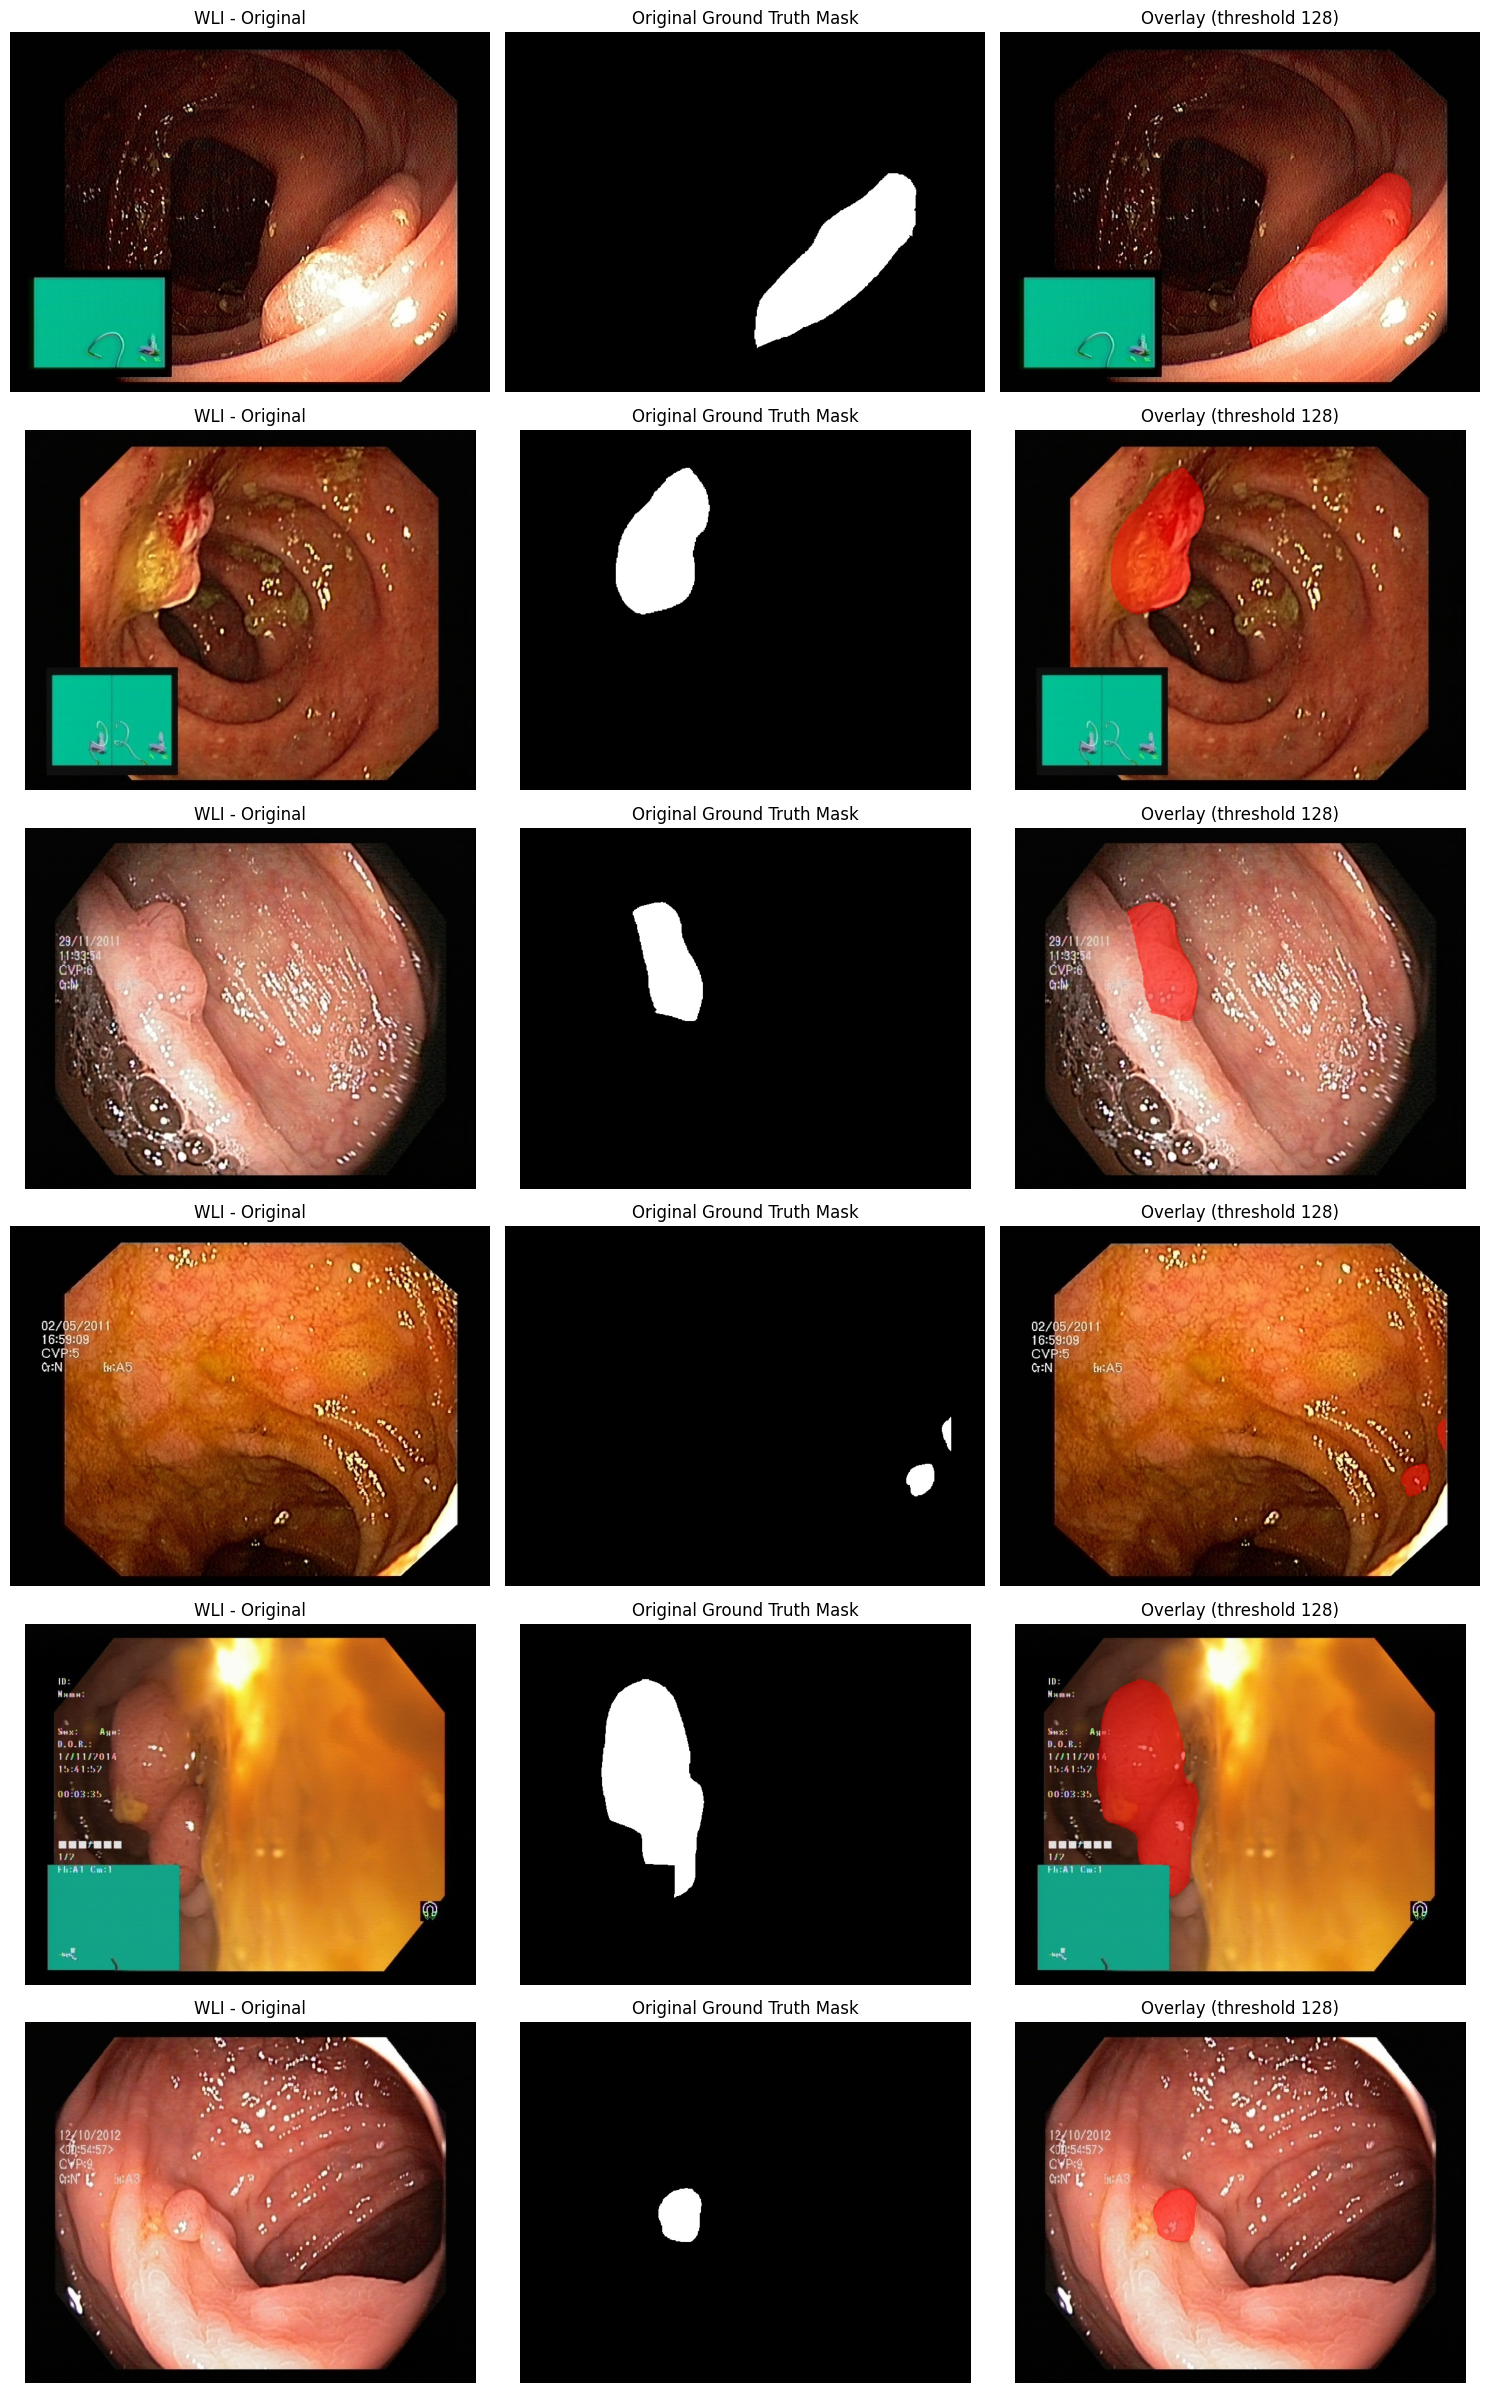

In [56]:
# ============================================
# STEP 5: VISUALIZE IMAGE AND MASK
# ============================================

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

samples = pairs_df.sample(n=6, random_state=42)

fig, axes = plt.subplots(6, 3, figsize=(15, 24))

for i, (_, row) in enumerate(samples.iterrows()):

    image = np.array(
        Image.open(row["image_path"]).convert("RGB")
    )

    mask = np.array(
        Image.open(row["mask_path"]).convert("L")
    )

    # Candidate binary mask for visualization only
    binary_mask = mask >= 128

    # Red overlay
    overlay = image.copy()
    overlay[binary_mask] = (
        0.5 * overlay[binary_mask] +
        0.5 * np.array([255, 0, 0])
    ).astype(np.uint8)

    axes[i, 0].imshow(image)
    axes[i, 0].set_title(f"{row['modality']} - Original")

    axes[i, 1].imshow(mask, cmap="gray", vmin=0, vmax=255)
    axes[i, 1].set_title("Original Ground Truth Mask")

    axes[i, 2].imshow(overlay)
    axes[i, 2].set_title("Overlay (threshold 128)")

    for j in range(3):
        axes[i, j].axis("off")

plt.tight_layout()
plt.show()

In [57]:
from sklearn.model_selection import train_test_split

print("train_test_split imported successfully!")

train_test_split imported successfully!


In [58]:
# ============================================
# STEP 6: TRAIN VALIDATION SPLIT
# ============================================

train_df, val_df = train_test_split(
    pairs_df,
    test_size=0.20,
    random_state=42,
    stratify=pairs_df["modality"]
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)

print("Training samples:", len(train_df))
print("Validation samples:", len(val_df))

print("\nTraining distribution:")
print(train_df["modality"].value_counts())

print("\nValidation distribution:")
print(val_df["modality"].value_counts())

Training samples: 3147
Validation samples: 787

Training distribution:
modality
WLI     2870
NBI      117
FICE      56
BLI       56
LCI       48
Name: count, dtype: int64

Validation distribution:
modality
WLI     718
NBI      29
BLI      14
FICE     14
LCI      12
Name: count, dtype: int64


In [59]:
from torch.utils.data import Dataset
import torchvision.transforms.functional as TF
from torchvision.transforms import InterpolationMode
import random
import numpy as np
import torch
from PIL import Image

print("All required imports successful!")

All required imports successful!


In [60]:
# ============================================
# STEP 7: DATASET AND AUGMENTATION
# ============================================

import torchvision.transforms.functional as TF
from torchvision.transforms import InterpolationMode
import random

IMAGE_SIZE = 224

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]


class PolypDataset(Dataset):

    def __init__(self, dataframe, training=False):
        self.dataframe = dataframe.reset_index(drop=True)
        self.training = training

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):

        row = self.dataframe.iloc[idx]

        image = Image.open(row["image_path"]).convert("RGB")
        mask = Image.open(row["mask_path"]).convert("L")

        # Resize image and mask
        image = TF.resize(
            image,
            [IMAGE_SIZE, IMAGE_SIZE],
            interpolation=InterpolationMode.BILINEAR
        )

        mask = TF.resize(
            mask,
            [IMAGE_SIZE, IMAGE_SIZE],
            interpolation=InterpolationMode.NEAREST
        )

        # Synchronized augmentation
        if self.training:

            if random.random() > 0.5:
                image = TF.hflip(image)
                mask = TF.hflip(mask)

            if random.random() > 0.5:
                image = TF.rotate(
                    image, 15,
                    interpolation=InterpolationMode.BILINEAR
                )
                mask = TF.rotate(
                    mask, 15,
                    interpolation=InterpolationMode.NEAREST
                )

        # Convert image to tensor
        image = TF.to_tensor(image)
        image = TF.normalize(
            image,
            mean=IMAGENET_MEAN,
            std=IMAGENET_STD
        )

        # Candidate binary mask
        mask = np.array(mask, dtype=np.uint8)
        mask = (mask >= 128).astype(np.float32)

        mask = torch.from_numpy(mask).unsqueeze(0)

        return image, mask

In [61]:
# ============================================
# STEP 8: DATASET TESTING
# ============================================

train_dataset = PolypDataset(
    train_df,
    training=True
)

val_dataset = PolypDataset(
    val_df,
    training=False
)

# Get one sample from each dataset
train_image, train_mask = train_dataset[0]
val_image, val_mask = val_dataset[0]

print("Training sample:")
print("Image shape:", train_image.shape)
print("Mask shape:", train_mask.shape)
print("Image dtype:", train_image.dtype)
print("Mask dtype:", train_mask.dtype)
print("Mask unique values:", torch.unique(train_mask))

print("\nValidation sample:")
print("Image shape:", val_image.shape)
print("Mask shape:", val_mask.shape)
print("Mask unique values:", torch.unique(val_mask))

Training sample:
Image shape: torch.Size([3, 224, 224])
Mask shape: torch.Size([1, 224, 224])
Image dtype: torch.float32
Mask dtype: torch.float32
Mask unique values: tensor([0., 1.])

Validation sample:
Image shape: torch.Size([3, 224, 224])
Mask shape: torch.Size([1, 224, 224])
Mask unique values: tensor([0., 1.])


In [62]:
from torch.utils.data import DataLoader

print("DataLoader imported successfully!")

DataLoader imported successfully!


In [63]:
# ============================================
# STEP 9: DATALOADER
# ============================================

BATCH_SIZE = 8
NUM_WORKERS = 2

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    drop_last=False
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    drop_last=False
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

# Inspect one batch
images, masks = next(iter(train_loader))

print("\nBatch inspection:")
print("Images:", images.shape)
print("Masks:", masks.shape)
print("Image dtype:", images.dtype)
print("Mask dtype:", masks.dtype)
print("Mask values:", torch.unique(masks))

Training batches: 394
Validation batches: 99

Batch inspection:
Images: torch.Size([8, 3, 224, 224])
Masks: torch.Size([8, 1, 224, 224])
Image dtype: torch.float32
Mask dtype: torch.float32
Mask values: tensor([0., 1.])


In [64]:
import torch
import torch.nn as nn
import torchvision
from pathlib import Path

print("Torch:", torch.__version__)
print("Torchvision:", torchvision.__version__)

Torch: 2.11.0+cu128
Torchvision: 0.26.0+cu128


In [65]:
import torch

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: Tesla T4


In [66]:
# ============================================
# STEP 10: LOAD PRETRAINED VIT
# ============================================

CHECKPOINT_PATH = Path(
    "/kaggle/input/models/pritydas825/"
    "visiontransformer/pytorch/default/1/"
    "vit_b_16-c867db91.pth"
)

print("Checkpoint exists:", CHECKPOINT_PATH.exists())


if not CHECKPOINT_PATH.exists():
    raise FileNotFoundError("Pretrained ViT checkpoint not found!")

weights = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=True
)

vit_encoder = torchvision.models.vit_b_16(weights=None)

vit_encoder.load_state_dict(weights, strict=True)

# Remove classification head
vit_encoder.heads = nn.Identity()

vit_encoder = vit_encoder.to(DEVICE)

print("\nPretrained ViT loaded successfully!")
print("Hidden dimension:", vit_encoder.hidden_dim)
print("Patch size:", vit_encoder.patch_size)
print("Number of encoder layers:", len(vit_encoder.encoder.layers))

Checkpoint exists: True

Pretrained ViT loaded successfully!
Hidden dimension: 768
Patch size: 16
Number of encoder layers: 12


In [67]:
# Step 11: Verify ViT feature extraction

vit_encoder.eval()

with torch.no_grad():
    dummy_input = torch.randn(2, 3, IMAGE_SIZE, IMAGE_SIZE).to(DEVICE)

    features = vit_encoder._process_input(dummy_input)

    # Add class token
    batch_class_token = vit_encoder.class_token.expand(dummy_input.shape[0], -1, -1)
    features = torch.cat([batch_class_token, features], dim=1)

    # Transformer encoder
    features = vit_encoder.encoder(features)

    # Remove class token
    patch_features = features[:, 1:, :]

    # Reshape tokens into spatial feature map
    patch_features = patch_features.transpose(1, 2)
    patch_features = patch_features.reshape(2, 768, 14, 14)

print("ViT feature shape:", patch_features.shape)

ViT feature shape: torch.Size([2, 768, 14, 14])


In [68]:
# Step 12: CNN Encoder

class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),

            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)


class CNNEncoder(nn.Module):
    def __init__(self):
        super().__init__()

        self.stem = ConvBlock(3, 32)       # 224 x 224
        self.pool1 = nn.MaxPool2d(2)

        self.encoder1 = ConvBlock(32, 64)  # 112 x 112
        self.pool2 = nn.MaxPool2d(2)

        self.encoder2 = ConvBlock(64, 128) # 56 x 56
        self.pool3 = nn.MaxPool2d(2)

        self.encoder3 = ConvBlock(128, 256) # 28 x 28
        self.pool4 = nn.MaxPool2d(2)

        self.encoder4 = ConvBlock(256, 384) # 14 x 14

    def forward(self, x):
        skip0 = self.stem(x)                       # 224 x 224
        skip1 = self.encoder1(self.pool1(skip0))   # 112 x 112
        skip2 = self.encoder2(self.pool2(skip1))   # 56 x 56
        skip3 = self.encoder3(self.pool3(skip2))   # 28 x 28
        bottleneck = self.encoder4(self.pool4(skip3)) # 14 x 14

        return skip0, skip1, skip2, skip3, bottleneck


cnn_encoder = CNNEncoder().to(DEVICE)

with torch.no_grad():
    dummy_input = torch.randn(2, 3, IMAGE_SIZE, IMAGE_SIZE).to(DEVICE)
    cnn_features = cnn_encoder(dummy_input)

print("CNN encoder feature shapes:")
for i, feature in enumerate(cnn_features):
    print(f"Feature {i}: {feature.shape}")

CNN encoder feature shapes:
Feature 0: torch.Size([2, 32, 224, 224])
Feature 1: torch.Size([2, 64, 112, 112])
Feature 2: torch.Size([2, 128, 56, 56])
Feature 3: torch.Size([2, 256, 28, 28])
Feature 4: torch.Size([2, 384, 14, 14])


In [69]:
# Step 13: ViT-CNN Feature Fusion

class ViTCNNFusion(nn.Module):
    def __init__(self, vit_channels=768, cnn_channels=384, fusion_channels=384):
        super().__init__()

        self.vit_projection = nn.Sequential(
            nn.Conv2d(vit_channels, 256, kernel_size=1, bias=False),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True)
        )

        self.fusion = ConvBlock(256 + cnn_channels, fusion_channels)

    def forward(self, vit_features, cnn_features):
        vit_features = self.vit_projection(vit_features)

        fused = torch.cat([vit_features, cnn_features], dim=1)

        return self.fusion(fused)


fusion_module = ViTCNNFusion().to(DEVICE)

with torch.no_grad():
    fused_features = fusion_module(
        patch_features,
        cnn_features[-1]
    )

print("ViT feature shape:", patch_features.shape)
print("CNN bottleneck shape:", cnn_features[-1].shape)
print("Fused feature shape:", fused_features.shape)

ViT feature shape: torch.Size([2, 768, 14, 14])
CNN bottleneck shape: torch.Size([2, 384, 14, 14])
Fused feature shape: torch.Size([2, 384, 14, 14])


In [70]:
# Step 14: U-Net Decoder with Skip Connections

class DecoderBlock(nn.Module):
    def __init__(self, in_channels, skip_channels, out_channels):
        super().__init__()

        self.conv = ConvBlock(
            in_channels + skip_channels,
            out_channels
        )

    def forward(self, x, skip):
        x = nn.functional.interpolate(
            x,
            size=skip.shape[2:],
            mode="bilinear",
            align_corners=False
        )

        x = torch.cat([x, skip], dim=1)

        return self.conv(x)


class UNetDecoder(nn.Module):
    def __init__(self):
        super().__init__()

        self.decoder3 = DecoderBlock(384, 256, 256)  # 14 -> 28
        self.decoder2 = DecoderBlock(256, 128, 128)  # 28 -> 56
        self.decoder1 = DecoderBlock(128, 64, 64)    # 56 -> 112
        self.decoder0 = DecoderBlock(64, 32, 32)     # 112 -> 224

        self.output_head = nn.Conv2d(
            32,
            1,
            kernel_size=1
        )

    def forward(self, fused, skips):
        skip0, skip1, skip2, skip3 = skips

        x = self.decoder3(fused, skip3)
        x = self.decoder2(x, skip2)
        x = self.decoder1(x, skip1)
        x = self.decoder0(x, skip0)

        return self.output_head(x)


decoder = UNetDecoder().to(DEVICE)

with torch.no_grad():
    decoder_output = decoder(
        fused_features,
        cnn_features[:4]
    )

print("Decoder output shape:", decoder_output.shape)

Decoder output shape: torch.Size([2, 1, 224, 224])


In [71]:
# Step 15: Complete Hybrid U-Net-ViT Model

class HybridUNetViT(nn.Module):
    def __init__(self, vit_encoder):
        super().__init__()

        self.vit_encoder = vit_encoder
        self.cnn_encoder = CNNEncoder()
        self.fusion = ViTCNNFusion()
        self.decoder = UNetDecoder()

        # Freeze pretrained ViT initially
        for param in self.vit_encoder.parameters():
            param.requires_grad = False

    def extract_vit_features(self, x):
        # Frozen ViT does not need gradient calculation
        with torch.no_grad():
            features = self.vit_encoder._process_input(x)

            class_token = self.vit_encoder.class_token.expand(
                x.shape[0], -1, -1
            )

            features = torch.cat(
                [class_token, features],
                dim=1
            )

            features = self.vit_encoder.encoder(features)

            # Remove class token
            features = features[:, 1:, :]

            # Convert tokens into 2D feature map
            features = features.transpose(1, 2)

            features = features.reshape(
                x.shape[0], 768, 14, 14
            )

        return features

    def forward(self, x):
        vit_features = self.extract_vit_features(x)

        cnn_features = self.cnn_encoder(x)

        fused_features = self.fusion(
            vit_features,
            cnn_features[-1]
        )

        output = self.decoder(
            fused_features,
            cnn_features[:4]
        )

        return output


model = HybridUNetViT(vit_encoder).to(DEVICE)

print("Hybrid U-Net-ViT model created successfully!")

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
print(
    f"Frozen parameters: "
    f"{total_params - trainable_params:,}"
)

Hybrid U-Net-ViT model created successfully!
Total parameters: 95,763,329
Trainable parameters: 9,964,673
Frozen parameters: 85,798,656


In [72]:
# Step 16: Complete Model Forward Pass Test

model.eval()

images, masks = next(iter(train_loader))

images = images.to(DEVICE)
masks = masks.to(DEVICE)

with torch.no_grad():
    outputs = model(images)

print("Input images:", images.shape)
print("Ground-truth masks:", masks.shape)
print("Model predictions:", outputs.shape)

print("Output dtype:", outputs.dtype)
print("Output contains NaN:", torch.isnan(outputs).any().item())
print("Output contains Inf:", torch.isinf(outputs).any().item())

Input images: torch.Size([8, 3, 224, 224])
Ground-truth masks: torch.Size([8, 1, 224, 224])
Model predictions: torch.Size([8, 1, 224, 224])
Output dtype: torch.float32
Output contains NaN: False
Output contains Inf: False


In [73]:
# Step 17: Combined BCE + Dice Loss

class BCEDiceLoss(nn.Module):
    def __init__(self, bce_weight=0.5, dice_weight=0.5, smooth=1e-6):
        super().__init__()

        self.bce = nn.BCEWithLogitsLoss()
        self.bce_weight = bce_weight
        self.dice_weight = dice_weight
        self.smooth = smooth

    def forward(self, logits, targets):
        bce_loss = self.bce(logits, targets)

        probabilities = torch.sigmoid(logits)

        probabilities = probabilities.flatten(1)
        targets = targets.flatten(1)

        intersection = (probabilities * targets).sum(dim=1)

        dice = (
            2.0 * intersection + self.smooth
        ) / (
            probabilities.sum(dim=1)
            + targets.sum(dim=1)
            + self.smooth
        )

        dice_loss = 1.0 - dice.mean()

        total_loss = (
            self.bce_weight * bce_loss
            + self.dice_weight * dice_loss
        )

        return total_loss


criterion = BCEDiceLoss()

with torch.no_grad():
    sample_loss = criterion(outputs, masks)

print("BCE + Dice Loss:", sample_loss.item())

BCE + Dice Loss: 0.7636183500289917


In [74]:
# Step 18: Optimizer Configuration

LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4

optimizer = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

print("Optimizer: AdamW")
print("Learning rate:", LEARNING_RATE)
print("Weight decay:", WEIGHT_DECAY)

print(
    "Trainable parameters:",
    sum(p.numel() for p in model.parameters() if p.requires_grad)
)

Optimizer: AdamW
Learning rate: 0.0001
Weight decay: 0.0001
Trainable parameters: 9964673


In [75]:
# Step 19: Inspect filenames for possible patient/sequence identifiers

import os
import re

for modality in sorted(pairs_df["modality"].unique()):
    subset = pairs_df[pairs_df["modality"] == modality]

    print(f"\n{'='*50}")
    print(f"Modality: {modality}")
    print(f"Total images: {len(subset)}")
    print("Sample filenames:")

    for path in subset["image_path"].head(15):
        print(" ", os.path.basename(path))

    stems = [
        os.path.splitext(os.path.basename(path))[0]
        for path in subset["image_path"]
    ]

    print("Unique filename stems:", len(set(stems)))
    print("Duplicate stems:", len(stems) - len(set(stems)))


Modality: BLI
Total images: 70
Sample filenames:
  PKHL_15 220831_201026_BN032_027.jpg
  PKHL_15 220831_201026_BN032_033.jpg
  PKHL_15 220831_201026_BN032_035.jpg
  PKHL_15 220831_201026_BN036_012.jpg
  PKHL_15 220831_201026_BN038_003.jpg
  PKHL_15 220831_201026_BN038_011.jpg
  PKHL_15 220831_201027_BN087_010.jpg
  PKHL_15 220831_201027_BN087_011.jpg
  PKHL_15 220831_201027_BN087_023.jpg
  PKHL_15 220831_201027_BN087_028.jpg
  PKHL_15 220831_201027_BN093_011.jpg
  PKHL_15 220831_201027_BN093_012.jpg
  PKHL_15 220831_201028_BN003_048.jpg
  PKHL_15 220831_201028_BN003_051.jpg
  PKHL_15 220831_201028_BN012_021.jpg
Unique filename stems: 70
Duplicate stems: 0

Modality: FICE
Total images: 70
Sample filenames:
  HMUH_15 201129_201111_BN001_001.jpg
  HMUH_15 201129_201111_BN001_002.jpg
  HMUH_15 201129_201111_BN001_003.jpg
  HMUH_15 201129_201111_BN001_004.jpg
  HMUH_15 201129_201111_BN001_005.jpg
  HMUH_15 201129_201111_BN001_006.jpg
  HMUH_15 201129_201111_BN001_007.jpg
  HMUH_15 201129_2

In [76]:
# Step 20: Search for dataset metadata files

from pathlib import Path

DATASET_ROOT = Path(
    "/kaggle/input/datasets/farjanahaquechamok/"
    "multi-center-polypbd/PolypDB"
)

metadata_extensions = {
    ".csv", ".json", ".xlsx", ".xls",
    ".txt", ".xml", ".tsv"
}

metadata_files = [
    p for p in DATASET_ROOT.rglob("*")
    if p.is_file() and p.suffix.lower() in metadata_extensions
]

print("Metadata files found:", len(metadata_files))

for file in metadata_files[:100]:
    print(file.relative_to(DATASET_ROOT))

Metadata files found: 0


In [77]:
# Step 21: Inspect possible BN group identifiers

import re

for modality in ["BLI", "FICE", "LCI"]:
    subset = pairs_df[pairs_df["modality"] == modality]

    group_ids = []

    for path in subset["image_path"]:
        filename = os.path.basename(path)
        match = re.search(r"(BN\d+)_\d+", filename)

        group_ids.append(match.group(1) if match else None)

    print(f"\n{modality}")
    print("Total images:", len(group_ids))
    print("Identified BN groups:", sum(g is not None for g in group_ids))
    print("Unique BN groups:", len(set(g for g in group_ids if g)))
    print("Missing group IDs:", sum(g is None for g in group_ids))


BLI
Total images: 70
Identified BN groups: 70
Unique BN groups: 30
Missing group IDs: 0

FICE
Total images: 70
Identified BN groups: 70
Unique BN groups: 8
Missing group IDs: 0

LCI
Total images: 60
Identified BN groups: 60
Unique BN groups: 26
Missing group IDs: 0


In [78]:
# Step 22: Count images per BN group

import re
import os

for modality in ["BLI", "FICE", "LCI"]:
    subset = pairs_df[pairs_df["modality"] == modality].copy()

    subset["group_id"] = subset["image_path"].apply(
        lambda p: re.search(
            r"(BN\d+)_\d+",
            os.path.basename(p)
        ).group(1)
    )

    print(f"\n{modality} - Images per BN group")
    print(
        subset["group_id"]
        .value_counts()
        .sort_index()
        .to_string()
    )


BLI - Images per BN group
group_id
BN003    2
BN004    1
BN005    1
BN006    1
BN011    3
BN012    3
BN018    1
BN021    3
BN025    2
BN026    5
BN028    3
BN029    1
BN030    2
BN032    4
BN036    4
BN038    3
BN041    2
BN043    3
BN045    3
BN046    1
BN048    1
BN049    1
BN054    5
BN056    1
BN057    2
BN058    1
BN061    1
BN073    4
BN087    4
BN093    2

FICE - Images per BN group
group_id
BN001    21
BN002    14
BN003     4
BN004    10
BN005     8
BN006     1
BN007    10
BN008     2

LCI - Images per BN group
group_id
BN003    1
BN004    1
BN010    3
BN016    2
BN019    1
BN022    2
BN023    6
BN025    2
BN026    1
BN027    4
BN029    4
BN031    1
BN032    4
BN033    2
BN035    2
BN036    1
BN038    1
BN040    4
BN043    1
BN046    2
BN047    4
BN050    4
BN055    3
BN061    1
BN066    1
BN072    2


In [79]:
# Step 23: Group-aware 70/15/15 split

import re
import os
import numpy as np
from sklearn.model_selection import GroupShuffleSplit, train_test_split

df = pairs_df.copy().reset_index(drop=True)

df["group_id"] = None

group_modalities = ["BLI", "FICE", "LCI"]

for modality in group_modalities:
    mask = df["modality"] == modality

    df.loc[mask, "group_id"] = df.loc[mask, "image_path"].apply(
        lambda p: re.search(
            r"(BN\d+)_\d+",
            os.path.basename(p)
        ).group(1)
    )

train_parts = []
val_parts = []
test_parts = []

for modality in df["modality"].unique():

    subset = df[df["modality"] == modality].copy()

    if modality in group_modalities:

        # First split: 70% train, 30% temporary
        splitter1 = GroupShuffleSplit(
            n_splits=1,
            test_size=0.30,
            random_state=42
        )

        train_idx, temp_idx = next(
            splitter1.split(
                subset,
                groups=subset["group_id"]
            )
        )

        train_part = subset.iloc[train_idx]
        temp_part = subset.iloc[temp_idx]

        # Split temporary data into validation and test
        splitter2 = GroupShuffleSplit(
            n_splits=1,
            test_size=0.50,
            random_state=42
        )

        val_idx, test_idx = next(
            splitter2.split(
                temp_part,
                groups=temp_part["group_id"]
            )
        )

        val_part = temp_part.iloc[val_idx]
        test_part = temp_part.iloc[test_idx]

    else:

        train_part, temp_part = train_test_split(
            subset,
            test_size=0.30,
            random_state=42
        )

        val_part, test_part = train_test_split(
            temp_part,
            test_size=0.50,
            random_state=42
        )

    train_parts.append(train_part)
    val_parts.append(val_part)
    test_parts.append(test_part)


train_df = pd.concat(train_parts).sample(
    frac=1, random_state=42
).reset_index(drop=True)

val_df = pd.concat(val_parts).sample(
    frac=1, random_state=42
).reset_index(drop=True)

test_df = pd.concat(test_parts).sample(
    frac=1, random_state=42
).reset_index(drop=True)

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))
print("Total:", len(train_df) + len(val_df) + len(test_df))

Train: 2739
Validation: 578
Test: 617
Total: 3934


In [80]:
# Step 24: Split integrity verification

splits = {
    "train": train_df,
    "validation": val_df,
    "test": test_df
}

print("MODALITY DISTRIBUTION")
for split_name, split_df in splits.items():
    print(f"\n{split_name.upper()}")
    print(split_df["modality"].value_counts().sort_index())

print("\nBN GROUP LEAKAGE CHECK")

for modality in ["BLI", "FICE", "LCI"]:
    group_sets = {}

    for split_name, split_df in splits.items():
        group_sets[split_name] = set(
            split_df.loc[
                split_df["modality"] == modality,
                "group_id"
            ].dropna()
        )

    train_val = group_sets["train"] & group_sets["validation"]
    train_test = group_sets["train"] & group_sets["test"]
    val_test = group_sets["validation"] & group_sets["test"]

    print(f"\n{modality}")
    print("Train-Val overlap:", train_val)
    print("Train-Test overlap:", train_test)
    print("Val-Test overlap:", val_test)

    assert not train_val
    assert not train_test
    assert not val_test

all_paths = (
    train_df["image_path"].tolist()
    + val_df["image_path"].tolist()
    + test_df["image_path"].tolist()
)

print("\nTotal paths:", len(all_paths))
print("Unique paths:", len(set(all_paths)))

assert len(all_paths) == 3934
assert len(set(all_paths)) == 3934

print("\nAll integrity checks passed!")

MODALITY DISTRIBUTION

TRAIN
modality
BLI       44
FICE      34
LCI       48
NBI      102
WLI     2511
Name: count, dtype: int64

VALIDATION
modality
BLI      10
FICE      1
LCI       7
NBI      22
WLI     538
Name: count, dtype: int64

TEST
modality
BLI      16
FICE     35
LCI       5
NBI      22
WLI     539
Name: count, dtype: int64

BN GROUP LEAKAGE CHECK

BLI
Train-Val overlap: set()
Train-Test overlap: set()
Val-Test overlap: set()

FICE
Train-Val overlap: set()
Train-Test overlap: set()
Val-Test overlap: set()

LCI
Train-Val overlap: set()
Train-Test overlap: set()
Val-Test overlap: set()

Total paths: 3934
Unique paths: 3934

All integrity checks passed!


In [81]:
# Step 25: Optimize group-aware 70/15/15 split

from sklearn.model_selection import GroupShuffleSplit, train_test_split
import numpy as np
import pandas as pd

group_modalities = ["BLI", "FICE", "LCI"]

train_parts, val_parts, test_parts = [], [], []

for modality in sorted(df["modality"].unique()):

    subset = df[df["modality"] == modality].copy()

    if modality in group_modalities:

        best_score = float("inf")
        best_split = None

        for seed in range(500):

            # Reserve approximately 15% for test
            split1 = GroupShuffleSplit(
                n_splits=1,
                test_size=0.15,
                random_state=seed
            )

            remaining_idx, test_idx = next(
                split1.split(subset, groups=subset["group_id"])
            )

            remaining = subset.iloc[remaining_idx]
            test_part = subset.iloc[test_idx]

            # Reserve approximately 15% overall for validation
            split2 = GroupShuffleSplit(
                n_splits=1,
                test_size=0.15 / 0.85,
                random_state=seed
            )

            train_idx, val_idx = next(
                split2.split(
                    remaining,
                    groups=remaining["group_id"]
                )
            )

            train_part = remaining.iloc[train_idx]
            val_part = remaining.iloc[val_idx]

            counts = np.array([
                len(train_part),
                len(val_part),
                len(test_part)
            ])

            targets = np.array([
                0.70, 0.15, 0.15
            ]) * len(subset)

            score = np.abs(counts - targets).sum()

            if score < best_score:
                best_score = score
                best_split = (
                    train_part.copy(),
                    val_part.copy(),
                    test_part.copy()
                )

        train_part, val_part, test_part = best_split

    else:
        # WLI and NBI: stratified random split by modality
        train_part, temp_part = train_test_split(
            subset,
            test_size=0.30,
            random_state=42
        )

        val_part, test_part = train_test_split(
            temp_part,
            test_size=0.50,
            random_state=42
        )

    train_parts.append(train_part)
    val_parts.append(val_part)
    test_parts.append(test_part)

train_df = pd.concat(train_parts).sample(
    frac=1, random_state=42
).reset_index(drop=True)

val_df = pd.concat(val_parts).sample(
    frac=1, random_state=42
).reset_index(drop=True)

test_df = pd.concat(test_parts).sample(
    frac=1, random_state=42
).reset_index(drop=True)

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

for name, part in [
    ("TRAIN", train_df),
    ("VALIDATION", val_df),
    ("TEST", test_df)
]:
    print(f"\n{name} modality distribution:")
    print(part["modality"].value_counts().sort_index())

Train: 2753
Validation: 590
Test: 591

TRAIN modality distribution:
modality
BLI       49
FICE      49
LCI       42
NBI      102
WLI     2511
Name: count, dtype: int64

VALIDATION modality distribution:
modality
BLI      10
FICE     11
LCI       9
NBI      22
WLI     538
Name: count, dtype: int64

TEST modality distribution:
modality
BLI      11
FICE     10
LCI       9
NBI      22
WLI     539
Name: count, dtype: int64


In [82]:
# Step 27: Rebuild Dataset and DataLoaders

import random
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms.functional as TF
from torchvision.transforms import InterpolationMode
from PIL import Image

class PolypDataset(Dataset):
    def __init__(self, dataframe, training=False):
        self.dataframe = dataframe.reset_index(drop=True)
        self.training = training

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        row = self.dataframe.iloc[idx]

        image = Image.open(row["image_path"]).convert("RGB")
        mask = Image.open(row["mask_path"]).convert("L")

        image = TF.resize(
            image, [IMAGE_SIZE, IMAGE_SIZE],
            interpolation=InterpolationMode.BILINEAR
        )

        mask = TF.resize(
            mask, [IMAGE_SIZE, IMAGE_SIZE],
            interpolation=InterpolationMode.NEAREST
        )

        if self.training:
            if random.random() > 0.5:
                image = TF.hflip(image)
                mask = TF.hflip(mask)

            angle = random.uniform(-15, 15)
            image = TF.rotate(
                image, angle,
                interpolation=InterpolationMode.BILINEAR
            )
            mask = TF.rotate(
                mask, angle,
                interpolation=InterpolationMode.NEAREST
            )

        image = TF.to_tensor(image)
        image = TF.normalize(
            image,
            mean=IMAGENET_MEAN,
            std=IMAGENET_STD
        )

        mask = np.array(mask, dtype=np.uint8)
        mask = (mask >= 128).astype(np.float32)
        mask = torch.from_numpy(mask).unsqueeze(0)

        return image, mask


train_dataset = PolypDataset(train_df, training=True)
val_dataset = PolypDataset(val_df, training=False)
test_dataset = PolypDataset(test_df, training=False)

BATCH_SIZE = 8
NUM_WORKERS = 2

generator = torch.Generator()
generator.manual_seed(42)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    generator=generator
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

images, masks = next(iter(train_loader))

print("\nBatch image shape:", images.shape)
print("Batch mask shape:", masks.shape)
print("Mask values:", torch.unique(masks))

Training batches: 345
Validation batches: 74
Test batches: 74

Batch image shape: torch.Size([8, 3, 224, 224])
Batch mask shape: torch.Size([8, 1, 224, 224])
Mask values: tensor([0., 1.])


In [83]:
# Step 28: Evaluation Metrics (Device-safe)

def calculate_metrics(logits, targets, threshold=0.5, smooth=1e-7):

    targets = targets.to(logits.device)

    probabilities = torch.sigmoid(logits)
    predictions = (probabilities >= threshold).float()

    predictions = predictions.flatten(1)
    targets = targets.flatten(1)

    intersection = (predictions * targets).sum(dim=1)

    pred_sum = predictions.sum(dim=1)
    target_sum = targets.sum(dim=1)

    dice = (
        2 * intersection + smooth
    ) / (
        pred_sum + target_sum + smooth
    )

    iou = (
        intersection + smooth
    ) / (
        pred_sum + target_sum - intersection + smooth
    )

    precision = (
        intersection + smooth
    ) / (
        pred_sum + smooth
    )

    recall = (
        intersection + smooth
    ) / (
        target_sum + smooth
    )

    return {
        "dice": dice.mean().item(),
        "iou": iou.mean().item(),
        "precision": precision.mean().item(),
        "recall": recall.mean().item()
    }


with torch.no_grad():
    sample_metrics = calculate_metrics(outputs, masks)

print("Initial sample metrics:")

for name, value in sample_metrics.items():
    print(f"{name.capitalize()}: {value:.4f}")

Initial sample metrics:
Dice: 0.0000
Iou: 0.0000
Precision: 1.0000
Recall: 0.0000


In [84]:
# Step 29: Corrected Evaluation Metrics

def calculate_metrics(logits, targets, threshold=0.5, smooth=1e-7):

    targets = targets.to(logits.device)

    probabilities = torch.sigmoid(logits)
    predictions = (probabilities >= threshold).float()

    predictions = predictions.flatten(1)
    targets = targets.flatten(1)

    intersection = (predictions * targets).sum(dim=1)

    pred_sum = predictions.sum(dim=1)
    target_sum = targets.sum(dim=1)

    dice = (
        2 * intersection + smooth
    ) / (
        pred_sum + target_sum + smooth
    )

    iou = (
        intersection + smooth
    ) / (
        pred_sum + target_sum - intersection + smooth
    )

    precision = torch.where(
        pred_sum > 0,
        intersection / pred_sum.clamp_min(smooth),
        torch.zeros_like(pred_sum)
    )

    recall = (
        intersection / target_sum.clamp_min(smooth)
    )

    return {
        "dice": dice.mean().item(),
        "iou": iou.mean().item(),
        "precision": precision.mean().item(),
        "recall": recall.mean().item()
    }


with torch.no_grad():
    sample_metrics = calculate_metrics(outputs, masks)

for name, value in sample_metrics.items():
    print(f"{name.capitalize()}: {value:.4f}")

Dice: 0.0000
Iou: 0.0000
Precision: 0.0000
Recall: 0.0000


In [85]:
# Step 30: Fresh Batch Sanity Check

model.eval()

images, masks = next(iter(train_loader))

images = images.to(DEVICE)
masks = masks.to(DEVICE)

with torch.no_grad():
    outputs = model(images)

sample_metrics = calculate_metrics(outputs, masks)

print("Fresh batch shapes:")
print("Images:", images.shape)
print("Masks:", masks.shape)
print("Predictions:", outputs.shape)

print("\nInitial metrics:")
for name, value in sample_metrics.items():
    print(f"{name.capitalize()}: {value:.4f}")

print("\nPrediction probability range:")
print("Minimum:", torch.sigmoid(outputs).min().item())
print("Maximum:", torch.sigmoid(outputs).max().item())

Fresh batch shapes:
Images: torch.Size([8, 3, 224, 224])
Masks: torch.Size([8, 1, 224, 224])
Predictions: torch.Size([8, 1, 224, 224])

Initial metrics:
Dice: 0.0000
Iou: 0.0000
Precision: 0.0000
Recall: 0.0000

Prediction probability range:
Minimum: 0.46773168444633484
Maximum: 0.47810158133506775


In [86]:
# Step 31: Training Configuration

NUM_EPOCHS = 30
PATIENCE = 7

BEST_MODEL_PATH = "/kaggle/working/best_hybrid_unet_vit.pth"

print("Epochs:", NUM_EPOCHS)
print("Early stopping patience:", PATIENCE)
print("Best model will be saved at:", BEST_MODEL_PATH)
print("Device:", DEVICE)

Epochs: 30
Early stopping patience: 7
Best model will be saved at: /kaggle/working/best_hybrid_unet_vit.pth
Device: cuda


In [87]:
# Step 32: Learning Rate Scheduler

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2,
    min_lr=1e-7
)

print("Scheduler initialized successfully!")
print("Initial learning rate:", optimizer.param_groups[0]["lr"])

Scheduler initialized successfully!
Initial learning rate: 0.0001


In [88]:
# Step 33: Automatic Mixed Precision Setup

USE_AMP = (DEVICE.type == "cuda")

if USE_AMP:
    scaler = torch.amp.GradScaler("cuda")
else:
    scaler = None

print("Mixed Precision Enabled:", USE_AMP)
print("Gradient Scaler:", scaler is not None)

Mixed Precision Enabled: True
Gradient Scaler: True


In [89]:
# Step 34: Training Function

def train_one_epoch(model, loader, criterion, optimizer, scaler, device):

    model.train()

    running_loss = 0.0
    running_dice = 0.0
    total_samples = 0

    for images, masks in loader:

        images = images.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.amp.autocast(
            device_type="cuda",
            enabled=(device.type == "cuda")
        ):
            outputs = model(images)
            loss = criterion(outputs, masks)

        if scaler is not None:
            scaler.scale(loss).backward()

            scaler.unscale_(optimizer)

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=1.0
            )

            scaler.step(optimizer)
            scaler.update()

        else:
            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=1.0
            )

            optimizer.step()

        with torch.no_grad():
            batch_metrics = calculate_metrics(outputs, masks)

        batch_size = images.size(0)

        running_loss += loss.item() * batch_size
        running_dice += batch_metrics["dice"] * batch_size
        total_samples += batch_size

    return {
        "loss": running_loss / total_samples,
        "dice": running_dice / total_samples
    }


print("Training function defined successfully!")

Training function defined successfully!


In [90]:
# Step 35: Validation Function

def validate_one_epoch(model, loader, criterion, device):

    model.eval()

    running_loss = 0.0
    running_dice = 0.0
    total_samples = 0

    with torch.no_grad():

        for images, masks in loader:

            images = images.to(device, non_blocking=True)
            masks = masks.to(device, non_blocking=True)

            with torch.amp.autocast(
                device_type="cuda",
                enabled=(device.type == "cuda")
            ):
                outputs = model(images)
                loss = criterion(outputs, masks)

            batch_metrics = calculate_metrics(outputs, masks)

            batch_size = images.size(0)

            running_loss += loss.item() * batch_size
            running_dice += batch_metrics["dice"] * batch_size
            total_samples += batch_size

    return {
        "loss": running_loss / total_samples,
        "dice": running_dice / total_samples
    }


print("Validation function defined successfully!")

Validation function defined successfully!


In [91]:
# Step 36: Verify Model Parameters

frozen_count = 0
trainable_count = 0

for name, parameter in model.named_parameters():

    if parameter.requires_grad:
        trainable_count += parameter.numel()
    else:
        frozen_count += parameter.numel()

print("Frozen parameters:", f"{frozen_count:,}")
print("Trainable parameters:", f"{trainable_count:,}")

print("\nViT encoder frozen:",
      all(not p.requires_grad for p in model.vit_encoder.parameters()))

print("CNN encoder trainable:",
      any(p.requires_grad for p in model.cnn_encoder.parameters()))

print("Fusion layer trainable:",
      any(p.requires_grad for p in model.fusion.parameters()))

print("U-Net decoder trainable:",
      any(p.requires_grad for p in model.decoder.parameters()))

Frozen parameters: 85,798,656
Trainable parameters: 9,964,673

ViT encoder frozen: True
CNN encoder trainable: True
Fusion layer trainable: True
U-Net decoder trainable: True


In [92]:
# Step 37: Complete Automated Training Pipeline

import time
import copy
from pathlib import Path

MAX_EPOCHS = 30
EARLY_STOPPING_PATIENCE = 7

CHECKPOINT_DIR = Path("/kaggle/working/checkpoints")
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

BEST_MODEL_PATH = CHECKPOINT_DIR / "best_hybrid_unet_vit.pth"

history = {
    "train_loss": [],
    "train_dice": [],
    "val_loss": [],
    "val_dice": []
}

best_val_dice = -1.0
best_epoch = 0
epochs_without_improvement = 0

print("Starting automated training...")
print("=" * 65)

for epoch in range(1, MAX_EPOCHS + 1):

    start_time = time.time()

    # Training
    train_metrics = train_one_epoch(
        model, train_loader, criterion,
        optimizer, scaler, DEVICE
    )

    # Validation
    val_metrics = validate_one_epoch(
        model, val_loader, criterion, DEVICE
    )

    # Learning rate adjustment
    scheduler.step(val_metrics["loss"])

    # Save metrics
    history["train_loss"].append(train_metrics["loss"])
    history["train_dice"].append(train_metrics["dice"])
    history["val_loss"].append(val_metrics["loss"])
    history["val_dice"].append(val_metrics["dice"])

    # Best model checkpoint
    if val_metrics["dice"] > best_val_dice:

        best_val_dice = val_metrics["dice"]
        best_epoch = epoch
        epochs_without_improvement = 0

        torch.save({
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "scheduler_state_dict": scheduler.state_dict(),
            "scaler_state_dict": scaler.state_dict() if scaler else None,
            "best_val_dice": best_val_dice,
            "history": copy.deepcopy(history)
        }, BEST_MODEL_PATH)

        status = "Best model saved"

    else:
        epochs_without_improvement += 1
        status = "No improvement"

    elapsed = (time.time() - start_time) / 60

    print(f"\nEpoch {epoch}/{MAX_EPOCHS}")
    print(f"Train Loss: {train_metrics['loss']:.4f}")
    print(f"Train Dice: {train_metrics['dice']:.4f}")
    print(f"Val Loss: {val_metrics['loss']:.4f}")
    print(f"Val Dice: {val_metrics['dice']:.4f}")
    print(f"Learning Rate: {optimizer.param_groups[0]['lr']:.2e}")
    print(f"Time: {elapsed:.2f} minutes")
    print(f"Status: {status}")
    print(f"Best Val Dice: {best_val_dice:.4f} (Epoch {best_epoch})")

    if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:
        print("\nEarly stopping triggered.")
        break

print("\n" + "=" * 65)
print("TRAINING COMPLETED")
print("Best Epoch:", best_epoch)
print(f"Best Validation Dice: {best_val_dice:.4f}")
print("Checkpoint:", BEST_MODEL_PATH)

Starting automated training...

Epoch 1/30
Train Loss: 0.5150
Train Dice: 0.6258
Val Loss: 0.4605
Val Dice: 0.6995
Learning Rate: 1.00e-04
Time: 7.32 minutes
Status: Best model saved
Best Val Dice: 0.6995 (Epoch 1)

Epoch 2/30
Train Loss: 0.4200
Train Dice: 0.7292
Val Loss: 0.3936
Val Dice: 0.7240
Learning Rate: 1.00e-04
Time: 0.86 minutes
Status: Best model saved
Best Val Dice: 0.7240 (Epoch 2)

Epoch 3/30
Train Loss: 0.3519
Train Dice: 0.7636
Val Loss: 0.3281
Val Dice: 0.7658
Learning Rate: 1.00e-04
Time: 0.85 minutes
Status: Best model saved
Best Val Dice: 0.7658 (Epoch 3)

Epoch 4/30
Train Loss: 0.2907
Train Dice: 0.7966
Val Loss: 0.2746
Val Dice: 0.7773
Learning Rate: 1.00e-04
Time: 0.86 minutes
Status: Best model saved
Best Val Dice: 0.7773 (Epoch 4)

Epoch 5/30
Train Loss: 0.2413
Train Dice: 0.8134
Val Loss: 0.2289
Val Dice: 0.8062
Learning Rate: 1.00e-04
Time: 0.85 minutes
Status: Best model saved
Best Val Dice: 0.8062 (Epoch 5)

Epoch 6/30
Train Loss: 0.1994
Train Dice: 0.8325

In [93]:
# Step 38: Load Best Model for Final Evaluation

checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location=DEVICE,
    weights_only=True
)

model.load_state_dict(checkpoint["model_state_dict"])
model.to(DEVICE)
model.eval()
model.vit_encoder.eval()

print("Best model loaded successfully!")
print("Selected Epoch:", checkpoint["epoch"])
print(f"Best Validation Dice: {checkpoint['best_val_dice']:.4f}")
print("Model is in evaluation mode.")
print("Test samples:", len(test_dataset))

Best model loaded successfully!
Selected Epoch: 29
Best Validation Dice: 0.8448
Model is in evaluation mode.
Test samples: 591


In [94]:
# Step 39: Final Test Evaluation

import numpy as np
import torch

model.eval()

test_results = {
    "dice": [],
    "iou": [],
    "precision": [],
    "recall": []
}

with torch.no_grad():

    for images, masks in test_loader:

        images = images.to(DEVICE, non_blocking=True)
        masks = masks.to(DEVICE, non_blocking=True)

        with torch.amp.autocast(
            device_type="cuda",
            enabled=(DEVICE.type == "cuda")
        ):
            logits = model(images)

        batch_metrics = calculate_metrics(
            logits, masks, threshold=0.5
        )

        batch_size = images.size(0)

        # Store per-image metrics
        probabilities = torch.sigmoid(logits)
        predictions = (probabilities >= 0.5).float()

        for i in range(batch_size):

            single_metrics = calculate_metrics(
                logits[i:i+1],
                masks[i:i+1],
                threshold=0.5
            )

            for key in test_results:
                test_results[key].append(single_metrics[key])

print("Final Test Evaluation Completed!")
print("-" * 50)

for metric, values in test_results.items():

    values = np.array(values)

    print(
        f"{metric.upper():<12} "
        f"Mean: {values.mean():.4f} | "
        f"Std: {values.std():.4f}"
    )

print("-" * 50)
print("Total evaluated test images:", len(test_results["dice"]))

Final Test Evaluation Completed!
--------------------------------------------------
DICE         Mean: 0.8330 | Std: 0.2455
IOU          Mean: 0.7681 | Std: 0.2623
PRECISION    Mean: 0.8752 | Std: 0.2348
RECALL       Mean: 0.8413 | Std: 0.2551
--------------------------------------------------
Total evaluated test images: 591


In [95]:
# Step 41: Modality-wise Test Evaluation

import numpy as np
import pandas as pd
from torch.utils.data import DataLoader

model.eval()

modality_results = []

for modality in sorted(test_df["modality"].unique()):

    modality_df = test_df[
        test_df["modality"] == modality
    ].reset_index(drop=True)

    modality_dataset = PolypDataset(
        modality_df,
        training=False
    )

    modality_loader = DataLoader(
        modality_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=(DEVICE.type == "cuda")
    )

    scores = {
        "dice": [],
        "iou": [],
        "precision": [],
        "recall": []
    }

    with torch.no_grad():
        for images, masks in modality_loader:

            images = images.to(DEVICE, non_blocking=True)
            masks = masks.to(DEVICE, non_blocking=True)

            with torch.amp.autocast(
                device_type="cuda",
                enabled=(DEVICE.type == "cuda")
            ):
                logits = model(images)

            batch_size = images.size(0)

            for i in range(batch_size):

                metrics = calculate_metrics(
                    logits[i:i+1],
                    masks[i:i+1],
                    threshold=0.5
                )

                for key in scores:
                    scores[key].append(metrics[key])

    row = {
        "Modality": modality,
        "Images": len(modality_df)
    }

    for metric, values in scores.items():
        row[f"{metric.upper()} Mean"] = np.mean(values)
        row[f"{metric.upper()} Std"] = np.std(values)

    modality_results.append(row)

modality_results_df = pd.DataFrame(modality_results)

print("Modality-wise Test Evaluation Completed!")
display(modality_results_df.round(4))

Modality-wise Test Evaluation Completed!


,Modality,Images,DICE Mean,DICE Std,IOU Mean,IOU Std,PRECISION Mean,PRECISION Std,RECALL Mean,RECALL Std
0,BLI,11,0.6180,0.3344,0.5288,0.3401,0.7079,0.3393,0.6479,0.3536
1,FICE,10,0.8689,0.1622,0.7989,0.2145,0.9293,0.0486,0.8630,0.2413
2,LCI,9,0.9256,0.1013,0.8754,0.1471,0.9067,0.1506,0.9590,0.0266
3,NBI,22,0.7076,0.3121,0.6266,0.3320,0.8267,0.3038,0.7011,0.3340
4,WLI,539,0.8403,0.2395,0.7764,0.2551,0.8790,0.2306,0.8486,0.2475


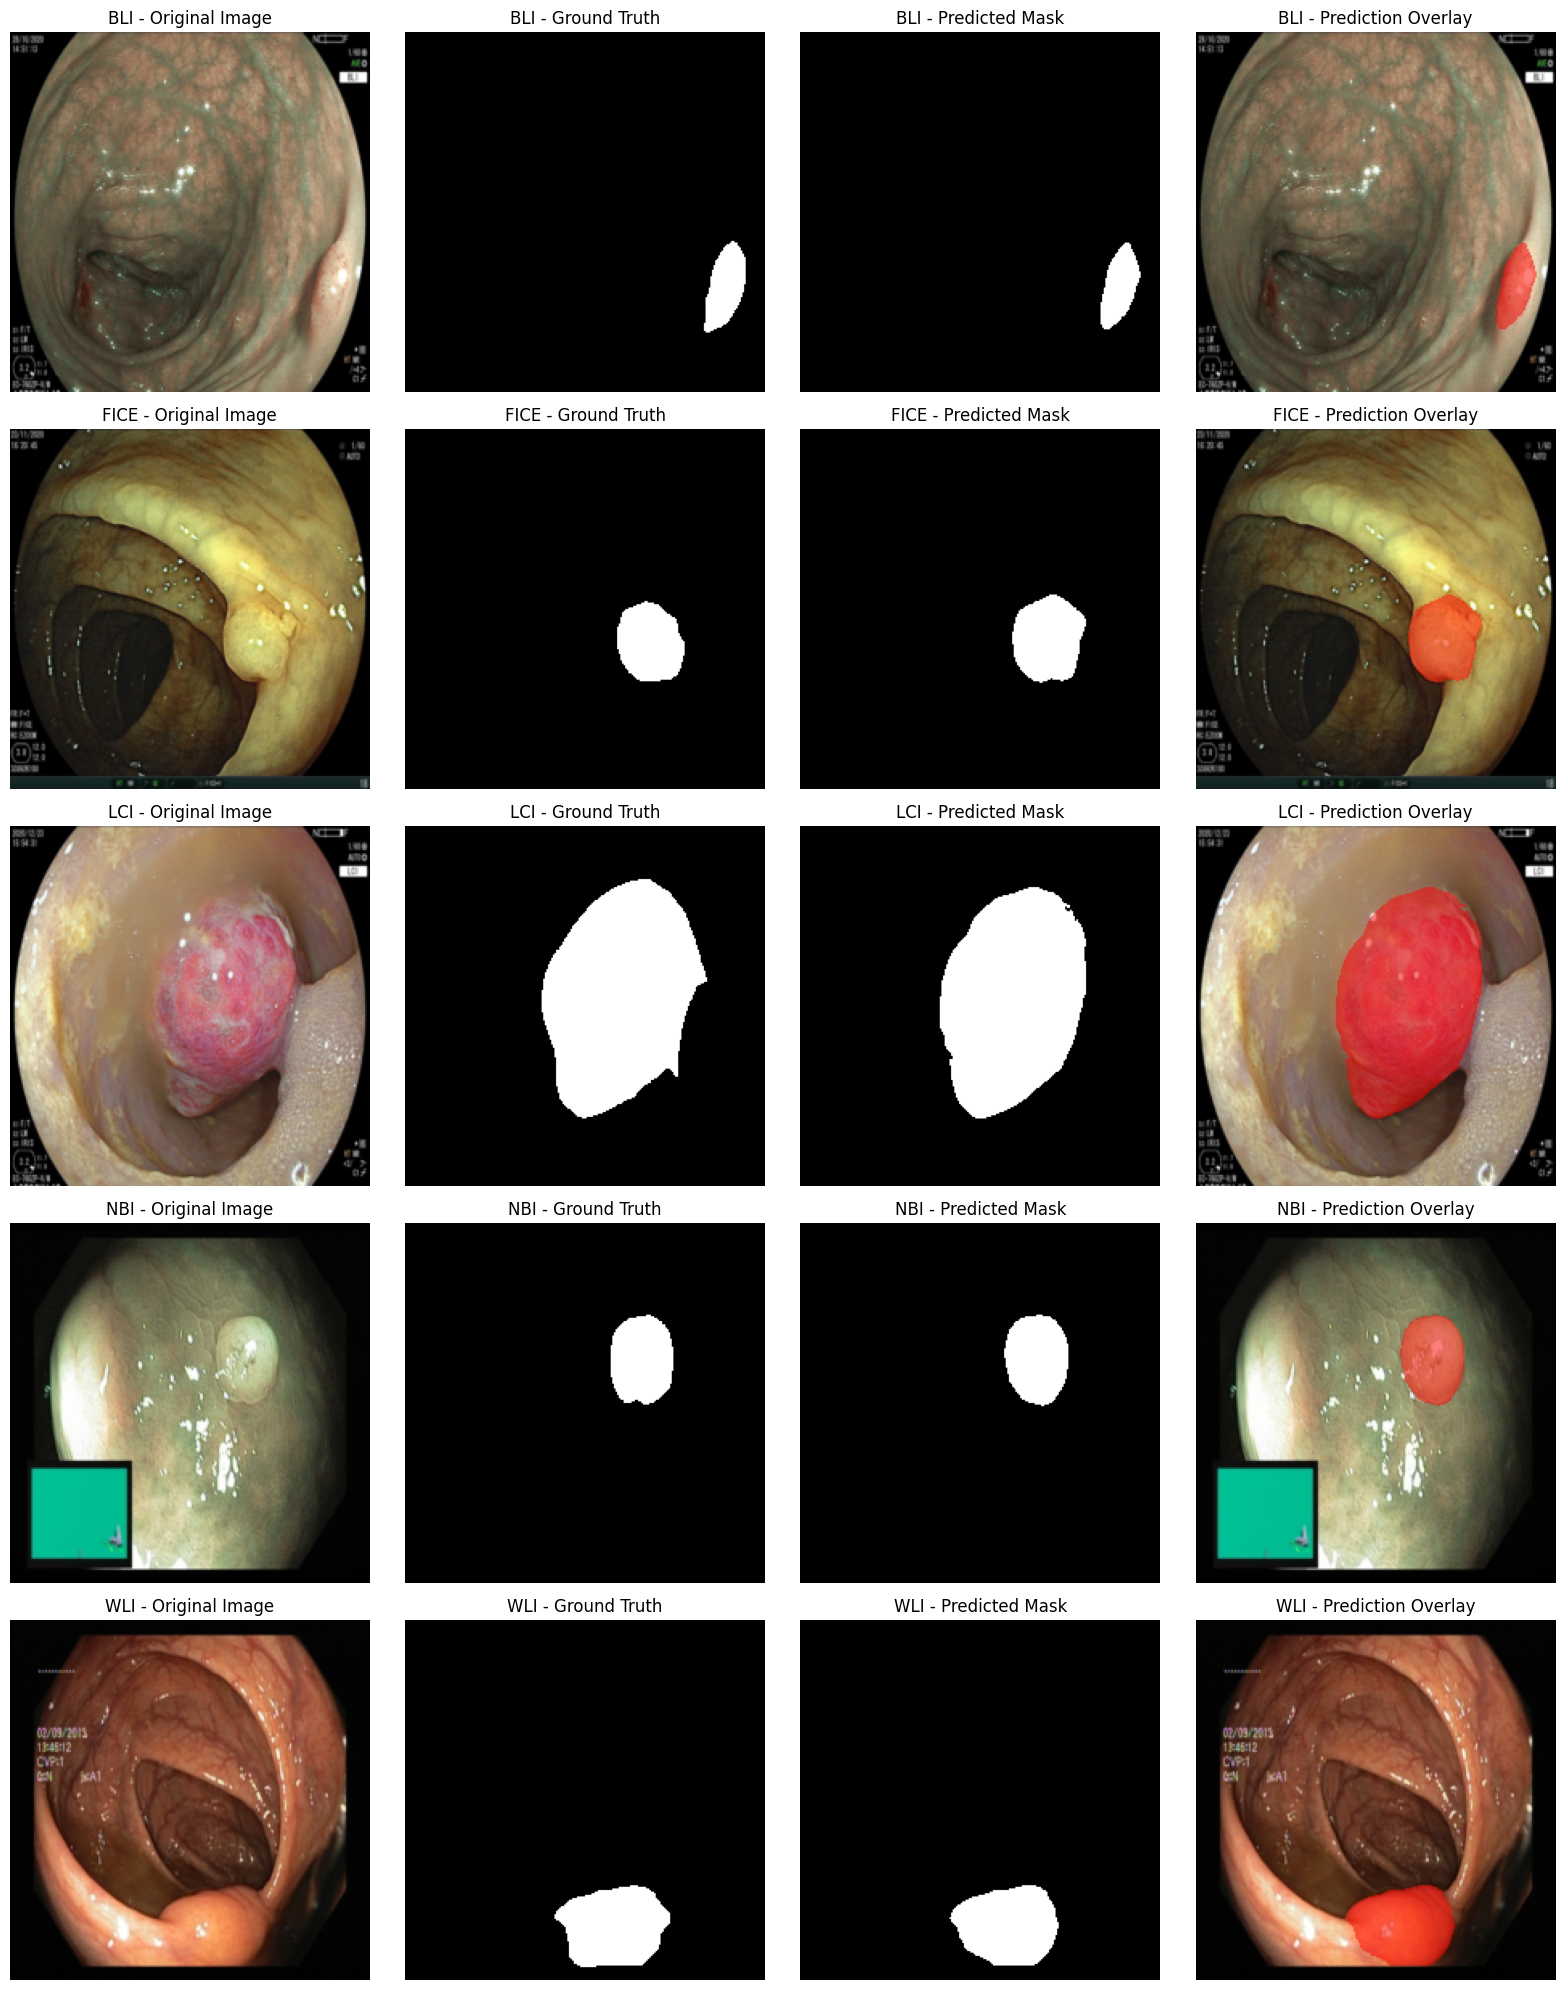

In [96]:
# Step 43: Qualitative Test Prediction Visualization

import matplotlib.pyplot as plt
import numpy as np
import torch

model.eval()

# Select one deterministic test sample from each modality
selected_indices = []

for modality in ["BLI", "FICE", "LCI", "NBI", "WLI"]:
    indices = test_df.index[
        test_df["modality"] == modality
    ].tolist()

    if indices:
        selected_indices.append((modality, indices[0]))

mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
std = torch.tensor(IMAGENET_STD).view(3, 1, 1)

fig, axes = plt.subplots(
    len(selected_indices), 4,
    figsize=(16, 4 * len(selected_indices))
)

if len(selected_indices) == 1:
    axes = np.expand_dims(axes, axis=0)

for row, (modality, idx) in enumerate(selected_indices):

    image_tensor, mask_tensor = test_dataset[idx]

    with torch.no_grad():
        input_tensor = image_tensor.unsqueeze(0).to(DEVICE)

        with torch.amp.autocast(
            device_type="cuda",
            enabled=(DEVICE.type == "cuda")
        ):
            logits = model(input_tensor)

        probability = torch.sigmoid(logits)
        prediction = (probability >= 0.5).float()

    # Restore original image colors
    image = (image_tensor * std + mean).clamp(0, 1)
    image = image.permute(1, 2, 0).cpu().numpy()

    ground_truth = mask_tensor.squeeze().cpu().numpy()
    predicted_mask = prediction.squeeze().cpu().numpy()

    overlay = image.copy()
    overlay[predicted_mask > 0] = (
        0.5 * overlay[predicted_mask > 0]
        + 0.5 * np.array([1, 0, 0])
    )

    panels = [
        (image, "Original Image"),
        (ground_truth, "Ground Truth"),
        (predicted_mask, "Predicted Mask"),
        (overlay, "Prediction Overlay")
    ]

    for col, (content, title) in enumerate(panels):
        axes[row, col].imshow(
            content,
            cmap="gray" if col in [1, 2] else None
        )
        axes[row, col].set_title(
            f"{modality} - {title}"
        )
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()

In [97]:
import os

DATASET_ROOT = (
    "/kaggle/input/datasets/farjanahaquechamok/"
    "multi-center-polypbd/PolypDB/PolypDB_modality_wise"
)

for modality in ["BLI", "FICE", "LCI", "NBI", "WLI"]:
    modality_path = os.path.join(DATASET_ROOT, modality)
    print(modality, ":", os.listdir(modality_path)[:10])

BLI : ['images', 'masks']
FICE : ['images', 'masks']
LCI : ['images', 'masks']
NBI : ['images', 'masks']
WLI : ['images', 'masks']


In [98]:
import os
import re
import random
import numpy as np
import pandas as pd

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

DATASET_ROOT = (
    "/kaggle/input/datasets/farjanahaquechamok/"
    "multi-center-polypbd/PolypDB/PolypDB_modality_wise"
)

records = []

for modality in ["BLI", "FICE", "LCI", "NBI", "WLI"]:
    image_dir = os.path.join(DATASET_ROOT, modality, "images")
    mask_dir = os.path.join(DATASET_ROOT, modality, "masks")

    image_files = {
        os.path.splitext(f)[0]: f
        for f in os.listdir(image_dir)
        if f.lower().endswith((".png", ".jpg", ".jpeg"))
    }

    mask_files = {
        os.path.splitext(f)[0]: f
        for f in os.listdir(mask_dir)
        if f.lower().endswith((".png", ".jpg", ".jpeg"))
    }

    matched_stems = sorted(set(image_files) & set(mask_files))

    for stem in matched_stems:
        match = re.search(r"(BN\d+)_\d+", stem)
        group_id = match.group(1) if match else stem

        records.append({
            "modality": modality,
            "image_path": os.path.join(image_dir, image_files[stem]),
            "mask_path": os.path.join(mask_dir, mask_files[stem]),
            "group_id": group_id
        })

df = pd.DataFrame(records)

print("Total matched pairs:", len(df))
print("\nModality distribution:")
print(df.groupby("modality").size())

print("\nGroup ID examples:")
print(df.groupby("modality")["group_id"].nunique())

display(df.head())

Total matched pairs: 3934

Modality distribution:
modality
BLI       70
FICE      70
LCI       60
NBI      146
WLI     3588
dtype: int64

Group ID examples:
modality
BLI       30
FICE       8
LCI       26
NBI      146
WLI     2671
Name: group_id, dtype: int64


,modality,image_path,mask_path,group_id
0,BLI,/kaggle/input/datasets/farjanahaquechamok/mult...,/kaggle/input/datasets/farjanahaquechamok/mult...,BN032
1,BLI,/kaggle/input/datasets/farjanahaquechamok/mult...,/kaggle/input/datasets/farjanahaquechamok/mult...,BN032
2,BLI,/kaggle/input/datasets/farjanahaquechamok/mult...,/kaggle/input/datasets/farjanahaquechamok/mult...,BN032
3,BLI,/kaggle/input/datasets/farjanahaquechamok/mult...,/kaggle/input/datasets/farjanahaquechamok/mult...,BN036
4,BLI,/kaggle/input/datasets/farjanahaquechamok/mult...,/kaggle/input/datasets/farjanahaquechamok/mult...,BN038


In [99]:
from sklearn.model_selection import GroupShuffleSplit, train_test_split

train_parts = []
val_parts = []
test_parts = []

for modality in ["BLI", "FICE", "LCI"]:
    subset = df[df["modality"] == modality].reset_index(drop=True)

    # 70% train, 30% temporary
    splitter1 = GroupShuffleSplit(
        n_splits=1, test_size=0.30, random_state=42
    )
    train_idx, temp_idx = next(
        splitter1.split(subset, groups=subset["group_id"])
    )

    train_mod = subset.iloc[train_idx]
    temp_mod = subset.iloc[temp_idx]

    # Split temporary set equally into validation and test
    splitter2 = GroupShuffleSplit(
        n_splits=1, test_size=0.50, random_state=42
    )
    val_idx, test_idx = next(
        splitter2.split(temp_mod, groups=temp_mod["group_id"])
    )

    train_parts.append(train_mod)
    val_parts.append(temp_mod.iloc[val_idx])
    test_parts.append(temp_mod.iloc[test_idx])


for modality in ["NBI", "WLI"]:
    subset = df[df["modality"] == modality].reset_index(drop=True)

    train_mod, temp_mod = train_test_split(
        subset, test_size=0.30, random_state=42, shuffle=True
    )

    val_mod, test_mod = train_test_split(
        temp_mod, test_size=0.50, random_state=42, shuffle=True
    )

    train_parts.append(train_mod)
    val_parts.append(val_mod)
    test_parts.append(test_mod)


train_df = pd.concat(train_parts).sample(frac=1, random_state=42).reset_index(drop=True)
val_df = pd.concat(val_parts).sample(frac=1, random_state=42).reset_index(drop=True)
test_df = pd.concat(test_parts).sample(frac=1, random_state=42).reset_index(drop=True)

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

print("\nTrain modality distribution:")
print(train_df["modality"].value_counts())

print("\nValidation modality distribution:")
print(val_df["modality"].value_counts())

print("\nTest modality distribution:")
print(test_df["modality"].value_counts())

Train: 2739
Validation: 578
Test: 617

Train modality distribution:
modality
WLI     2511
NBI      102
LCI       48
BLI       44
FICE      34
Name: count, dtype: int64

Validation modality distribution:
modality
WLI     538
NBI      22
BLI      10
LCI       7
FICE      1
Name: count, dtype: int64

Test modality distribution:
modality
WLI     539
FICE     35
NBI      22
BLI      16
LCI       5
Name: count, dtype: int64


In [100]:
# Check total count and duplicate image paths
all_paths = (
    train_df["image_path"].tolist()
    + val_df["image_path"].tolist()
    + test_df["image_path"].tolist()
)

print("Total:", len(all_paths))
print("Unique:", len(set(all_paths)))
print("Duplicate paths:", len(all_paths) - len(set(all_paths)))

# Check group overlap for BLI, FICE, LCI
for modality in ["BLI", "FICE", "LCI"]:
    tr = set(train_df.loc[train_df.modality == modality, "group_id"])
    va = set(val_df.loc[val_df.modality == modality, "group_id"])
    te = set(test_df.loc[test_df.modality == modality, "group_id"])

    print(f"\n{modality}")
    print("Train-Val overlap:", len(tr & va))
    print("Train-Test overlap:", len(tr & te))
    print("Val-Test overlap:", len(va & te))

Total: 3934
Unique: 3934
Duplicate paths: 0

BLI
Train-Val overlap: 0
Train-Test overlap: 0
Val-Test overlap: 0

FICE
Train-Val overlap: 0
Train-Test overlap: 0
Val-Test overlap: 0

LCI
Train-Val overlap: 0
Train-Test overlap: 0
Val-Test overlap: 0


In [101]:
import os

SPLIT_DIR = "/kaggle/working/baseline_splits"
os.makedirs(SPLIT_DIR, exist_ok=True)

train_df.to_csv(f"{SPLIT_DIR}/train.csv", index=False)
val_df.to_csv(f"{SPLIT_DIR}/validation.csv", index=False)
test_df.to_csv(f"{SPLIT_DIR}/test.csv", index=False)

print("Saved split files:")
print(os.listdir(SPLIT_DIR))

Saved split files:
['validation.csv', 'train.csv', 'test.csv']


In [102]:
import torch
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import torchvision.transforms as T
import torchvision.transforms.functional as TF
import pandas as pd
import numpy as np
import random

IMAGE_SIZE = 224
BATCH_SIZE = 8
NUM_WORKERS = 2

MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]

class PolypDataset(Dataset):
    def __init__(self, dataframe, training=False):
        self.df = dataframe.reset_index(drop=True)
        self.training = training

        self.image_transform = T.Compose([
            T.Resize(
                (IMAGE_SIZE, IMAGE_SIZE),
                interpolation=T.InterpolationMode.BILINEAR
            ),
            T.ToTensor(),
            T.Normalize(mean=MEAN, std=STD)
        ])

        self.mask_transform = T.Resize(
            (IMAGE_SIZE, IMAGE_SIZE),
            interpolation=T.InterpolationMode.NEAREST
        )

    def __len__(self):
        return len(self.df)

    def __getitem__(self, index):
        row = self.df.iloc[index]

        image = Image.open(row["image_path"]).convert("RGB")
        mask = Image.open(row["mask_path"]).convert("L")

        if self.training:
            if random.random() < 0.5:
                image = TF.hflip(image)
                mask = TF.hflip(mask)

            angle = random.uniform(-15, 15)
            image = TF.rotate(
                image, angle,
                interpolation=TF.InterpolationMode.BILINEAR
            )
            mask = TF.rotate(
                mask, angle,
                interpolation=TF.InterpolationMode.NEAREST
            )

        image = self.image_transform(image)
        mask = self.mask_transform(mask)

        mask = torch.from_numpy(
            (np.array(mask) >= 128).astype(np.float32)
        ).unsqueeze(0)

        return image, mask


train_dataset = PolypDataset(train_df, training=True)
val_dataset = PolypDataset(val_df, training=False)
test_dataset = PolypDataset(test_df, training=False)

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE,
    shuffle=True, num_workers=NUM_WORKERS,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE,
    shuffle=False, num_workers=NUM_WORKERS,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE,
    shuffle=False, num_workers=NUM_WORKERS,
    pin_memory=True
)

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

Train batches: 343
Validation batches: 73
Test batches: 78


In [103]:
import torch

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

images, masks = next(iter(train_loader))

print("Device:", DEVICE)
print("Image shape:", images.shape)
print("Mask shape:", masks.shape)
print("Image dtype:", images.dtype)
print("Mask dtype:", masks.dtype)
print("Mask unique values:", torch.unique(masks))
print("Image contains NaN:", torch.isnan(images).any().item())
print("Mask contains NaN:", torch.isnan(masks).any().item())

Device: cuda
Image shape: torch.Size([8, 3, 224, 224])
Mask shape: torch.Size([8, 1, 224, 224])
Image dtype: torch.float32
Mask dtype: torch.float32
Mask unique values: tensor([0., 1.])
Image contains NaN: False
Mask contains NaN: False


In [104]:
import torch
import torch.nn as nn

class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),

            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)


class UNet(nn.Module):
    def __init__(self, in_channels=3, out_channels=1):
        super().__init__()

        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

        # Encoder
        self.enc1 = DoubleConv(in_channels, 32)
        self.enc2 = DoubleConv(32, 64)
        self.enc3 = DoubleConv(64, 128)
        self.enc4 = DoubleConv(128, 256)

        # Bottleneck
        self.bottleneck = DoubleConv(256, 384)

        # Decoder
        self.up4 = nn.ConvTranspose2d(384, 256, kernel_size=2, stride=2)
        self.dec4 = DoubleConv(512, 256)

        self.up3 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2)
        self.dec3 = DoubleConv(256, 128)

        self.up2 = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)
        self.dec2 = DoubleConv(128, 64)

        self.up1 = nn.ConvTranspose2d(64, 32, kernel_size=2, stride=2)
        self.dec1 = DoubleConv(64, 32)

        self.final = nn.Conv2d(32, out_channels, kernel_size=1)

    def forward(self, x):
        # Encoder
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))

        # Bottleneck
        b = self.bottleneck(self.pool(e4))

        # Decoder with skip connections
        d4 = self.up4(b)
        d4 = self.dec4(torch.cat([d4, e4], dim=1))

        d3 = self.up3(d4)
        d3 = self.dec3(torch.cat([d3, e3], dim=1))

        d2 = self.up2(d3)
        d2 = self.dec2(torch.cat([d2, e2], dim=1))

        d1 = self.up1(d2)
        d1 = self.dec1(torch.cat([d1, e1], dim=1))

        return self.final(d1)


unet_model = UNet().to(DEVICE)

total_params = sum(p.numel() for p in unet_model.parameters())
trainable_params = sum(
    p.numel() for p in unet_model.parameters() if p.requires_grad
)

print("Total parameters:", f"{total_params:,}")
print("Trainable parameters:", f"{trainable_params:,}")

Total parameters: 6,304,353
Trainable parameters: 6,304,353


In [105]:
unet_model.eval()

with torch.no_grad():
    sample_images, sample_masks = next(iter(train_loader))
    sample_images = sample_images.to(DEVICE)

    outputs = unet_model(sample_images)

print("Input shape:", sample_images.shape)
print("Output shape:", outputs.shape)
print("Expected shape:", sample_masks.shape)
print("Output contains NaN:", torch.isnan(outputs).any().item())
print("Output contains Inf:", torch.isinf(outputs).any().item())

assert outputs.shape == sample_masks.shape
assert not torch.isnan(outputs).any()
assert not torch.isinf(outputs).any()

print("\nU-Net forward pass successful!")

Input shape: torch.Size([8, 3, 224, 224])
Output shape: torch.Size([8, 1, 224, 224])
Expected shape: torch.Size([8, 1, 224, 224])
Output contains NaN: False
Output contains Inf: False

U-Net forward pass successful!


In [106]:
import torch
import torch.nn as nn
import torch.optim as optim

class DiceLoss(nn.Module):
    def __init__(self, smooth=1.0):
        super().__init__()
        self.smooth = smooth

    def forward(self, logits, targets):
        probs = torch.sigmoid(logits)

        probs = probs.view(probs.size(0), -1)
        targets = targets.view(targets.size(0), -1)

        intersection = (probs * targets).sum(dim=1)

        dice = (
            2.0 * intersection + self.smooth
        ) / (
            probs.sum(dim=1) + targets.sum(dim=1) + self.smooth
        )

        return 1.0 - dice.mean()


class BCEDiceLoss(nn.Module):
    def __init__(self, bce_weight=0.5, dice_weight=0.5):
        super().__init__()
        self.bce = nn.BCEWithLogitsLoss()
        self.dice = DiceLoss()

        self.bce_weight = bce_weight
        self.dice_weight = dice_weight

    def forward(self, logits, targets):
        bce_loss = self.bce(logits, targets)
        dice_loss = self.dice(logits, targets)

        return (
            self.bce_weight * bce_loss
            + self.dice_weight * dice_loss
        )


criterion = BCEDiceLoss()

optimizer = optim.AdamW(
    unet_model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2,
    min_lr=1e-7
)

print("Loss function:", criterion)
print("Optimizer:", optimizer.__class__.__name__)
print("Initial learning rate:", optimizer.param_groups[0]["lr"])
print("Weight decay:", optimizer.param_groups[0]["weight_decay"])
print("Scheduler:", scheduler.__class__.__name__)

Loss function: BCEDiceLoss(
  (bce): BCEWithLogitsLoss()
  (dice): DiceLoss()
)
Optimizer: AdamW
Initial learning rate: 0.0001
Weight decay: 0.0001
Scheduler: ReduceLROnPlateau


In [107]:
import os
import numpy as np
from tqdm.auto import tqdm
from torch.amp import autocast, GradScaler

CHECKPOINT_DIR = "/kaggle/working/baseline_checkpoints"
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

BEST_MODEL_PATH = os.path.join(
    CHECKPOINT_DIR, "best_unet_baseline.pth"
)

scaler = GradScaler("cuda", enabled=(DEVICE.type == "cuda"))


def calculate_metrics(logits, targets, threshold=0.5, smooth=1e-7):
    probs = torch.sigmoid(logits)
    preds = (probs > threshold).float()

    preds = preds.view(preds.size(0), -1)
    targets = targets.view(targets.size(0), -1)

    intersection = (preds * targets).sum(dim=1)
    pred_sum = preds.sum(dim=1)
    target_sum = targets.sum(dim=1)

    dice = (2 * intersection + smooth) / (
        pred_sum + target_sum + smooth
    )

    iou = (intersection + smooth) / (
        pred_sum + target_sum - intersection + smooth
    )

    precision = (intersection + smooth) / (pred_sum + smooth)
    recall = (intersection + smooth) / (target_sum + smooth)

    return {
        "dice": dice.mean().item(),
        "iou": iou.mean().item(),
        "precision": precision.mean().item(),
        "recall": recall.mean().item()
    }


def train_one_epoch(model, loader, optimizer, criterion, scaler, device):
    model.train()

    total_loss = 0.0
    total_metrics = {
        "dice": 0.0, "iou": 0.0,
        "precision": 0.0, "recall": 0.0
    }
    total_samples = 0

    progress = tqdm(loader, desc="Training", leave=False)

    for images, masks in progress:
        images = images.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with autocast(
            device_type="cuda",
            enabled=(device.type == "cuda")
        ):
            logits = model(images)
            loss = criterion(logits, masks)

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)

        torch.nn.utils.clip_grad_norm_(
            model.parameters(), max_norm=1.0
        )

        scaler.step(optimizer)
        scaler.update()

        batch_size = images.size(0)
        total_samples += batch_size
        total_loss += loss.item() * batch_size

        metrics = calculate_metrics(logits.detach(), masks)

        for key in total_metrics:
            total_metrics[key] += metrics[key] * batch_size

        progress.set_postfix(loss=f"{loss.item():.4f}")

    return {
        "loss": total_loss / total_samples,
        **{k: v / total_samples for k, v in total_metrics.items()}
    }


def validate_one_epoch(model, loader, criterion, device):
    model.eval()

    total_loss = 0.0
    total_metrics = {
        "dice": 0.0, "iou": 0.0,
        "precision": 0.0, "recall": 0.0
    }
    total_samples = 0

    with torch.no_grad():
        for images, masks in tqdm(
            loader, desc="Validation", leave=False
        ):
            images = images.to(device, non_blocking=True)
            masks = masks.to(device, non_blocking=True)

            with autocast(
                device_type="cuda",
                enabled=(device.type == "cuda")
            ):
                logits = model(images)
                loss = criterion(logits, masks)

            batch_size = images.size(0)
            total_samples += batch_size
            total_loss += loss.item() * batch_size

            metrics = calculate_metrics(logits, masks)

            for key in total_metrics:
                total_metrics[key] += metrics[key] * batch_size

    return {
        "loss": total_loss / total_samples,
        **{k: v / total_samples for k, v in total_metrics.items()}
    }


print("Training and validation functions are ready.")
print("AMP enabled:", DEVICE.type == "cuda")
print("Checkpoint path:", BEST_MODEL_PATH)

Training and validation functions are ready.
AMP enabled: True
Checkpoint path: /kaggle/working/baseline_checkpoints/best_unet_baseline.pth


In [108]:
import time
import copy

MAX_EPOCHS = 30
EARLY_STOPPING_PATIENCE = 7

history = {
    "train_loss": [],
    "train_dice": [],
    "val_loss": [],
    "val_dice": [],
    "val_iou": [],
    "val_precision": [],
    "val_recall": [],
    "learning_rate": []
}

best_val_dice = -1.0
best_epoch = 0
epochs_without_improvement = 0

print("Starting U-Net baseline training...")
start_time = time.time()

for epoch in range(1, MAX_EPOCHS + 1):

    train_metrics = train_one_epoch(
        unet_model, train_loader,
        optimizer, criterion, scaler, DEVICE
    )

    val_metrics = validate_one_epoch(
        unet_model, val_loader, criterion, DEVICE
    )

    scheduler.step(val_metrics["loss"])

    current_lr = optimizer.param_groups[0]["lr"]

    history["train_loss"].append(train_metrics["loss"])
    history["train_dice"].append(train_metrics["dice"])
    history["val_loss"].append(val_metrics["loss"])
    history["val_dice"].append(val_metrics["dice"])
    history["val_iou"].append(val_metrics["iou"])
    history["val_precision"].append(val_metrics["precision"])
    history["val_recall"].append(val_metrics["recall"])
    history["learning_rate"].append(current_lr)

    print(
        f"\nEpoch [{epoch}/{MAX_EPOCHS}] "
        f"Train Loss: {train_metrics['loss']:.4f} | "
        f"Train Dice: {train_metrics['dice']:.4f} | "
        f"Val Loss: {val_metrics['loss']:.4f} | "
        f"Val Dice: {val_metrics['dice']:.4f} | "
        f"Val IoU: {val_metrics['iou']:.4f} | "
        f"LR: {current_lr:.7f}"
    )

    if val_metrics["dice"] > best_val_dice:
        best_val_dice = val_metrics["dice"]
        best_epoch = epoch
        epochs_without_improvement = 0

        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": unet_model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "best_val_dice": best_val_dice
            },
            BEST_MODEL_PATH
        )

        print("Best checkpoint saved.")

    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:
        print("\nEarly stopping triggered.")
        break

elapsed_time = (time.time() - start_time) / 60

print("\nTraining completed.")
print("Best epoch:", best_epoch)
print("Best validation Dice:", round(best_val_dice, 4))
print("Total training time (minutes):", round(elapsed_time, 2))
print("Checkpoint:", BEST_MODEL_PATH)

Starting U-Net baseline training...


Training:   0%|          | 0/343 [00:00<?, ?it/s]

Validation:   0%|          | 0/73 [00:00<?, ?it/s]


Epoch [1/30] Train Loss: 0.6857 | Train Dice: 0.3394 | Val Loss: 0.6262 | Val Dice: 0.4141 | Val IoU: 0.2952 | LR: 0.0001000
Best checkpoint saved.


Training:   0%|          | 0/343 [00:00<?, ?it/s]

...

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7827fd4cf1a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7827fd4cf1a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/


Epoch [29/30] Train Loss: 0.0920 | Train Dice: 0.8875 | Val Loss: 0.1689 | Val Dice: 0.7978 | Val IoU: 0.7253 | LR: 0.0000250


Training:   0%|          | 0/343 [00:00<?, ?it/s]

Validation:   0%|          | 0/73 [00:00<?, ?it/s]


Epoch [30/30] Train Loss: 0.0816 | Train Dice: 0.8997 | Val Loss: 0.1527 | Val Dice: 0.8157 | Val IoU: 0.7457 | LR: 0.0000250
Best checkpoint saved.

Training completed.
Best epoch: 30
Best validation Dice: 0.8157
Total training time (minutes): 44.94
Checkpoint: /kaggle/working/baseline_checkpoints/best_unet_baseline.pth


In [109]:
import os

checkpoint_path = "/kaggle/working/baseline_checkpoints/best_unet_baseline.pth"

print("Checkpoint exists:", os.path.isfile(checkpoint_path))
if os.path.isfile(checkpoint_path):
    print("File size (MB):", round(os.path.getsize(checkpoint_path) / (1024**2), 2))

Checkpoint exists: True
File size (MB): 72.26


In [111]:
import torch
import os

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BEST_MODEL_PATH = "/kaggle/working/baseline_checkpoints/best_unet_baseline.pth"

print("Device:", device)
print("Checkpoint exists:", os.path.isfile(BEST_MODEL_PATH))

checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location=device,
    weights_only=False
)

print("Checkpoint type:", type(checkpoint))

if isinstance(checkpoint, dict):
    print("Checkpoint keys:", list(checkpoint.keys()))

Device: cuda
Checkpoint exists: True
Checkpoint type: <class 'dict'>
Checkpoint keys: ['epoch', 'model_state_dict', 'optimizer_state_dict', 'best_val_dice']


In [112]:
print("Best epoch:", checkpoint["epoch"])
print("Best validation Dice:", checkpoint["best_val_dice"])

print("Number of parameter tensors:",
      len(checkpoint["model_state_dict"]))

print("First 10 parameter names:")
for key in list(checkpoint["model_state_dict"].keys())[:10]:
    print(key)

Best epoch: 30
Best validation Dice: 0.815681792048022
Number of parameter tensors: 118
First 10 parameter names:
enc1.block.0.weight
enc1.block.1.weight
enc1.block.1.bias
enc1.block.1.running_mean
enc1.block.1.running_var
enc1.block.1.num_batches_tracked
enc1.block.3.weight
enc1.block.4.weight
enc1.block.4.bias
enc1.block.4.running_mean


In [113]:
model = UNet().to(device)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("U-Net checkpoint loaded successfully!")

total_params = sum(p.numel() for p in model.parameters())
print("Total parameters:", f"{total_params:,}")

U-Net checkpoint loaded successfully!
Total parameters: 6,304,353


In [114]:
import pandas as pd
import os

TEST_CSV = "/kaggle/working/baseline_splits/test.csv"

test_df = pd.read_csv(TEST_CSV)

print("Test samples:", len(test_df))
print("\nModality distribution:")
print(test_df["modality"].value_counts())

print("\nColumns:")
print(test_df.columns.tolist())

print("\nFirst 3 rows:")
display(test_df.head(3))

Test samples: 617

Modality distribution:
modality
WLI     539
FICE     35
NBI      22
BLI      16
LCI       5
Name: count, dtype: int64

Columns:
['modality', 'image_path', 'mask_path', 'group_id']

First 3 rows:


,modality,image_path,mask_path,group_id
0,FICE,/kaggle/input/datasets/farjanahaquechamok/mult...,/kaggle/input/datasets/farjanahaquechamok/mult...,BN002
1,WLI,/kaggle/input/datasets/farjanahaquechamok/mult...,/kaggle/input/datasets/farjanahaquechamok/mult...,7c5c7bee-2395-4094-882c-5b2fe93c311d
2,WLI,/kaggle/input/datasets/farjanahaquechamok/mult...,/kaggle/input/datasets/farjanahaquechamok/mult...,0e6b4259-d82a-4671-922f-9af9e443194f


In [115]:
print("Test dataset size:", len(test_loader.dataset))
print("Test batches:", len(test_loader))

images, masks = next(iter(test_loader))

print("Image batch shape:", images.shape)
print("Mask batch shape:", masks.shape)
print("Image range:", images.min().item(), images.max().item())
print("Mask unique values:", torch.unique(masks))

Test dataset size: 617
Test batches: 78
Image batch shape: torch.Size([8, 3, 224, 224])
Mask batch shape: torch.Size([8, 1, 224, 224])
Image range: -2.1179039478302 2.640000104904175
Mask unique values: tensor([0., 1.])


In [116]:
import numpy as np
import torch
from tqdm.auto import tqdm

model.eval()

all_dice = []
all_iou = []
all_precision = []
all_recall = []

with torch.no_grad():
    for images, masks in tqdm(test_loader, desc="U-Net Test Evaluation"):
        images = images.to(device)
        masks = masks.to(device)

        with torch.cuda.amp.autocast(enabled=(device.type == "cuda")):
            logits = model(images)

        predictions = (torch.sigmoid(logits) > 0.5).float()

        for i in range(images.size(0)):
            pred = predictions[i].view(-1)
            target = masks[i].view(-1)

            intersection = (pred * target).sum().item()
            pred_sum = pred.sum().item()
            target_sum = target.sum().item()

            tp = intersection
            fp = pred_sum - tp
            fn = target_sum - tp

            smooth = 1e-6

            dice = (2 * tp + smooth) / (pred_sum + target_sum + smooth)
            iou = (tp + smooth) / (pred_sum + target_sum - tp + smooth)
            precision = (tp + smooth) / (tp + fp + smooth)
            recall = (tp + smooth) / (tp + fn + smooth)

            all_dice.append(dice)
            all_iou.append(iou)
            all_precision.append(precision)
            all_recall.append(recall)

print("\n===== U-Net Test Results =====")
print(f"Dice:      {np.mean(all_dice):.4f} ± {np.std(all_dice):.4f}")
print(f"IoU:       {np.mean(all_iou):.4f} ± {np.std(all_iou):.4f}")
print(f"Precision: {np.mean(all_precision):.4f} ± {np.std(all_precision):.4f}")
print(f"Recall:    {np.mean(all_recall):.4f} ± {np.std(all_recall):.4f}")
print("Evaluated images:", len(all_dice))

U-Net Test Evaluation:   0%|          | 0/78 [00:00<?, ?it/s]

/tmp/ipykernel_48/1926906012.py:17: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=(device.type == "cuda")):



===== U-Net Test Results =====
Dice:      0.8014 ± 0.2548
IoU:       0.7258 ± 0.2741
Precision: 0.8562 ± 0.2181
Recall:    0.8342 ± 0.2633
Evaluated images: 617


In [117]:
from torch.utils.data import SequentialSampler

print("Sequential test order:",
      isinstance(test_loader.sampler, SequentialSampler))

print("CSV rows:", len(test_df))
print("Test dataset rows:", len(test_loader.dataset))

Sequential test order: True
CSV rows: 617
Test dataset rows: 617


In [118]:
import pandas as pd
import numpy as np
import torch
from tqdm.auto import tqdm

model.eval()

results = []
image_index = 0

with torch.no_grad():
    for images, masks in tqdm(test_loader, desc="Modality-wise Evaluation"):
        images = images.to(device)
        masks = masks.to(device)

        with torch.amp.autocast("cuda", enabled=(device.type == "cuda")):
            logits = model(images)

        predictions = (torch.sigmoid(logits) > 0.5).float()

        for i in range(images.size(0)):
            pred = predictions[i].view(-1)
            target = masks[i].view(-1)

            tp = (pred * target).sum().item()
            pred_sum = pred.sum().item()
            target_sum = target.sum().item()

            fp = pred_sum - tp
            fn = target_sum - tp
            smooth = 1e-6

            results.append({
                "modality": test_df.iloc[image_index]["modality"],
                "dice": (2 * tp + smooth) / (pred_sum + target_sum + smooth),
                "iou": (tp + smooth) / (pred_sum + target_sum - tp + smooth),
                "precision": (tp + smooth) / (tp + fp + smooth),
                "recall": (tp + smooth) / (tp + fn + smooth)
            })

            image_index += 1

results_df = pd.DataFrame(results)

modality_results = results_df.groupby("modality").agg(
    Images=("dice", "count"),
    Dice_Mean=("dice", "mean"),
    Dice_Std=("dice", "std"),
    IoU_Mean=("iou", "mean"),
    IoU_Std=("iou", "std"),
    Precision_Mean=("precision", "mean"),
    Precision_Std=("precision", "std"),
    Recall_Mean=("recall", "mean"),
    Recall_Std=("recall", "std")
).round(4)

display(modality_results)

Modality-wise Evaluation:   0%|          | 0/78 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7827fd4cf1a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7827fd4cf1a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

,Images,Dice_Mean,Dice_Std,IoU_Mean,IoU_Std,Precision_Mean,Precision_Std,Recall_Mean,Recall_Std
modality,,,,,,,,,
BLI,16,0.4824,0.3407,0.3828,0.3138,0.8200,0.3032,0.4740,0.3842
FICE,35,0.7759,0.3179,0.7143,0.3226,0.8659,0.2062,0.8066,0.3378
LCI,5,0.8815,0.1047,0.7998,0.1561,0.8637,0.1955,0.9341,0.0776
NBI,22,0.6111,0.3290,0.5134,0.3294,0.7186,0.3181,0.6795,0.3472
WLI,539,0.8195,0.2357,0.7447,0.2582,0.8622,0.2103,0.8521,0.2411


In [119]:
import os

hybrid_path = "/kaggle/working/checkpoints/best_hybrid_unet_vit.pth"

print("Hybrid checkpoint exists:", os.path.isfile(hybrid_path))

if os.path.isfile(hybrid_path):
    print("Hybrid checkpoint size (MB):",
          round(os.path.getsize(hybrid_path) / (1024**2), 2))

Hybrid checkpoint exists: True
Hybrid checkpoint size (MB): 441.53


In [120]:
hybrid_checkpoint = torch.load(
    hybrid_path,
    map_location="cpu",
    weights_only=False
)

print("Checkpoint type:", type(hybrid_checkpoint))
print("Checkpoint keys:", list(hybrid_checkpoint.keys()))

if "model_state_dict" in hybrid_checkpoint:
    state = hybrid_checkpoint["model_state_dict"]
else:
    state = hybrid_checkpoint

print("\nNumber of parameter tensors:", len(state))
print("\nFirst 15 parameter names:")

for key in list(state.keys())[:15]:
    print(key)

Checkpoint type: <class 'dict'>
Checkpoint keys: ['epoch', 'model_state_dict', 'optimizer_state_dict', 'scheduler_state_dict', 'scaler_state_dict', 'best_val_dice', 'history']

Number of parameter tensors: 278

First 15 parameter names:
vit_encoder.class_token
vit_encoder.conv_proj.weight
vit_encoder.conv_proj.bias
vit_encoder.encoder.pos_embedding
vit_encoder.encoder.layers.encoder_layer_0.ln_1.weight
vit_encoder.encoder.layers.encoder_layer_0.ln_1.bias
vit_encoder.encoder.layers.encoder_layer_0.self_attention.in_proj_weight
vit_encoder.encoder.layers.encoder_layer_0.self_attention.in_proj_bias
vit_encoder.encoder.layers.encoder_layer_0.self_attention.out_proj.weight
vit_encoder.encoder.layers.encoder_layer_0.self_attention.out_proj.bias
vit_encoder.encoder.layers.encoder_layer_0.ln_2.weight
vit_encoder.encoder.layers.encoder_layer_0.ln_2.bias
vit_encoder.encoder.layers.encoder_layer_0.mlp.0.weight
vit_encoder.encoder.layers.encoder_layer_0.mlp.0.bias
vit_encoder.encoder.layers.encode

In [121]:
import inspect

for name, obj in globals().copy().items():
    if isinstance(obj, type) and (
        "hybrid" in name.lower() or "vit" in name.lower()
    ):
        print("Class found:", name)

Class found: ViTCNNFusion
Class found: HybridUNetViT


In [124]:
import torchvision.models as models
import torch.nn as nn

vit_encoder = models.vit_b_16(weights=None)

vit_encoder.load_state_dict(
    torch.load(
        "/kaggle/input/models/pritydas825/visiontransformer/pytorch/default/1/vit_b_16-c867db91.pth",
        map_location="cpu",
        weights_only=True
    ),
    strict=True
)

vit_encoder.heads = nn.Identity()

print("ViT-B/16 encoder loaded successfully!")
print("ViT output dimension:", vit_encoder.hidden_dim)

ViT-B/16 encoder loaded successfully!
ViT output dimension: 768


In [125]:
hybrid_model = HybridUNetViT(vit_encoder=vit_encoder).to(device)

hybrid_model.load_state_dict(
    hybrid_checkpoint["model_state_dict"],
    strict=True
)

hybrid_model.eval()

total_params = sum(p.numel() for p in hybrid_model.parameters())
trainable_params = sum(
    p.numel() for p in hybrid_model.parameters() if p.requires_grad
)

print("Hybrid checkpoint loaded successfully!")
print("Total parameters:", f"{total_params:,}")
print("Trainable parameters:", f"{trainable_params:,}")
print("Best epoch:", hybrid_checkpoint["epoch"])
print("Best validation Dice:", hybrid_checkpoint["best_val_dice"])

Hybrid checkpoint loaded successfully!
Total parameters: 95,763,329
Trainable parameters: 9,964,673
Best epoch: 29
Best validation Dice: 0.8448152590606173


In [126]:
import numpy as np
import torch
from tqdm.auto import tqdm

hybrid_model.eval()

hybrid_test_results = []

with torch.no_grad():
    for images, masks in tqdm(test_loader, desc="Hybrid Test Evaluation"):
        images = images.to(device)
        masks = masks.to(device)

        with torch.amp.autocast("cuda", enabled=(device.type == "cuda")):
            logits = hybrid_model(images)

        predictions = (torch.sigmoid(logits) > 0.5).float()

        for i in range(images.size(0)):
            pred = predictions[i].view(-1)
            target = masks[i].view(-1)

            tp = (pred * target).sum().item()
            pred_sum = pred.sum().item()
            target_sum = target.sum().item()

            fp = pred_sum - tp
            fn = target_sum - tp
            smooth = 1e-6

            hybrid_test_results.append({
                "dice": (2 * tp + smooth) / (pred_sum + target_sum + smooth),
                "iou": (tp + smooth) / (pred_sum + target_sum - tp + smooth),
                "precision": (tp + smooth) / (tp + fp + smooth),
                "recall": (tp + smooth) / (tp + fn + smooth)
            })

hybrid_results_df = pd.DataFrame(hybrid_test_results)

print("\n===== Hybrid U-Net + ViT: Test Results =====")
for metric in ["dice", "iou", "precision", "recall"]:
    print(
        f"{metric.capitalize():12s}: "
        f"{hybrid_results_df[metric].mean():.4f} "
        f"± {hybrid_results_df[metric].std(ddof=0):.4f}"
    )

print("Evaluated images:", len(hybrid_results_df))

Hybrid Test Evaluation:   0%|          | 0/78 [00:00<?, ?it/s]


===== Hybrid U-Net + ViT: Test Results =====
Dice        : 0.8403 ± 0.2400
Iou         : 0.7768 ± 0.2568
Precision   : 0.9043 ± 0.1818
Recall      : 0.8472 ± 0.2501
Evaluated images: 617


In [127]:
hybrid_results_df["modality"] = test_df["modality"].values

hybrid_modality_results = hybrid_results_df.groupby("modality").agg(
    Images=("dice", "count"),
    Dice_Mean=("dice", "mean"),
    Dice_Std=("dice", "std"),
    IoU_Mean=("iou", "mean"),
    IoU_Std=("iou", "std"),
    Precision_Mean=("precision", "mean"),
    Precision_Std=("precision", "std"),
    Recall_Mean=("recall", "mean"),
    Recall_Std=("recall", "std")
).round(4)

display(hybrid_modality_results)

,Images,Dice_Mean,Dice_Std,IoU_Mean,IoU_Std,Precision_Mean,Precision_Std,Recall_Mean,Recall_Std
modality,,,,,,,,,
BLI,16,0.7554,0.3024,0.6776,0.3131,0.8769,0.1525,0.7433,0.3329
FICE,35,0.9464,0.0692,0.9048,0.1037,0.9511,0.0425,0.9491,0.1020
LCI,5,0.9494,0.0455,0.9065,0.0788,0.9347,0.0907,0.9698,0.0245
NBI,22,0.7076,0.3194,0.6266,0.3398,0.8722,0.2518,0.7011,0.3418
WLI,539,0.8403,0.2397,0.7764,0.2553,0.9031,0.1854,0.8485,0.2478


In [128]:
import numpy as np
import pandas as pd
from scipy.stats import wilcoxon

unet_dice = np.asarray(all_dice, dtype=float)
hybrid_dice = hybrid_results_df["dice"].to_numpy(dtype=float)

# Paired image-level differences
dice_diff = hybrid_dice - unet_dice

# Paired bootstrap confidence interval
rng = np.random.default_rng(42)
n = len(dice_diff)
n_bootstrap = 10000

bootstrap_means = np.empty(n_bootstrap)

for b in range(n_bootstrap):
    indices = rng.integers(0, n, size=n)
    bootstrap_means[b] = dice_diff[indices].mean()

ci_low, ci_high = np.percentile(bootstrap_means, [2.5, 97.5])

# Wilcoxon signed-rank test
statistic, p_value = wilcoxon(
    hybrid_dice,
    unet_dice,
    alternative="greater"
)

print("===== Paired Statistical Analysis: Dice =====")
print("Number of paired images:", n)
print(f"Mean U-Net Dice: {unet_dice.mean():.4f}")
print(f"Mean Hybrid Dice: {hybrid_dice.mean():.4f}")
print(f"Mean paired improvement: {dice_diff.mean():.4f}")
print(f"95% Bootstrap CI: [{ci_low:.4f}, {ci_high:.4f}]")
print(f"Wilcoxon statistic: {statistic:.2f}")
print(f"One-sided p-value: {p_value:.6g}")
print("Hybrid better on:", int((dice_diff > 0).sum()), "images")
print("U-Net better on:", int((dice_diff < 0).sum()), "images")
print("Equal on:", int((dice_diff == 0).sum()), "images")

===== Paired Statistical Analysis: Dice =====
Number of paired images: 617
Mean U-Net Dice: 0.8014
Mean Hybrid Dice: 0.8403
Mean paired improvement: 0.0389
95% Bootstrap CI: [0.0214, 0.0563]
Wilcoxon statistic: 121289.00
One-sided p-value: 1.64553e-10
Hybrid better on: 386 images
U-Net better on: 226 images
Equal on: 5 images


In [129]:
import os
import numpy as np
import pandas as pd
from scipy.stats import wilcoxon

# Two-sided Wilcoxon test
stat_2s, p_2s = wilcoxon(
    hybrid_dice,
    unet_dice,
    alternative="two-sided"
)

# Per-image paired results
paired_df = test_df[["modality", "image_path", "mask_path"]].copy()

paired_df["unet_dice"] = unet_dice
paired_df["hybrid_dice"] = hybrid_dice
paired_df["dice_improvement"] = dice_diff

paired_df["unet_iou"] = all_iou
paired_df["hybrid_iou"] = hybrid_results_df["iou"].values

# Save research outputs
OUTPUT_DIR = "/kaggle/working/research_results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

paired_df.to_csv(
    f"{OUTPUT_DIR}/paired_test_results.csv",
    index=False
)

modality_results.to_csv(
    f"{OUTPUT_DIR}/unet_modality_results.csv"
)

hybrid_modality_results.to_csv(
    f"{OUTPUT_DIR}/hybrid_modality_results.csv"
)

summary = pd.DataFrame([{
    "test_images": len(paired_df),
    "unet_dice": unet_dice.mean(),
    "hybrid_dice": hybrid_dice.mean(),
    "mean_dice_improvement": dice_diff.mean(),
    "bootstrap_ci_lower": ci_low,
    "bootstrap_ci_upper": ci_high,
    "wilcoxon_statistic_two_sided": stat_2s,
    "wilcoxon_p_two_sided": p_2s,
    "hybrid_better_images": int((dice_diff > 0).sum()),
    "unet_better_images": int((dice_diff < 0).sum()),
    "equal_images": int((dice_diff == 0).sum())
}])

summary.to_csv(
    f"{OUTPUT_DIR}/statistical_summary.csv",
    index=False
)

print("Two-sided Wilcoxon p-value:", f"{p_2s:.8g}")
print("\nSaved files:")
for filename in os.listdir(OUTPUT_DIR):
    print(filename)

Two-sided Wilcoxon p-value: 3.2910691e-10

Saved files:
unet_modality_results.csv
statistical_summary.csv
hybrid_modality_results.csv
paired_test_results.csv
